

# Behavioral Customer Segmentation and Repeat Purchase Prediction

This notebook presents exploratory data analysis, customer behavioral segmentation, and 30-day repeat-purchase prediction using e-commerce event data from October 2019 through February 2020.



### Table of Contents

1. Setup and Data Loading
2. Exploratory Data Analysis (EDA)
3. Analysis Dataset Construction
4. Unsupervised Learning
5. Supervised Learning
6. Overall Findings and Limitations


## 1\. Setup and Data Loading

The dataset contains customer interaction events from a cosmetics e-commerce store, covering October 2019 through February 2020. Each monthly CSV file records user interactions, including product views, cart additions, cart removals, and purchases.

We load the five monthly files from Google Drive and combine them into a single DataFrame (all_df) for subsequent exploratory analysis and dataset construction.

In [ ]:
# Standard library
import os
import time
from pathlib import Path
from itertools import combinations

# Data processing and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Notebook utilities
from IPython.display import display, Markdown
from joblib import Parallel, delayed

# Scikit-learn
import sklearn
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Models
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
)

# Evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    brier_score_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Additional evaluation tools
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight

In [ ]:
# Global settings
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 110

In [ ]:
# Google Drive Mount
# [GitHub version] Original ran in Google Colab with Google Drive mounted.
# Here the data is read from the local ./data folder (see data/README.md).

DATA_DIR = Path("data")

Mounted at /content/drive


In [ ]:
#Load and Combine Monthly Data
files = [
    "2019-Oct.csv",
    "2019-Nov.csv",
    "2019-Dec.csv",
    "2020-Jan.csv",
    "2020-Feb.csv"
]

dfs = []

for file in files:
    temp = pd.read_csv(os.path.join(DATA_DIR, file))
    dfs.append(temp)

all_df = pd.concat(dfs, ignore_index=True)

del dfs, temp

print(f"\nCombined dataset: {len(all_df):,} rows")
print(f"Columns: {all_df.shape[1]}")


Combined dataset: 20,692,840 rows
Columns: 9


## 2\. Exploratory Data Analysis (EDA)

### 2.1. Examine the General Characteristics of the Raw Data

We first examined the overall structure and quality of the five-month dataset before making any modeling decisions.

In [ ]:
# Dataset overview
all_df["event_time"] = pd.to_datetime(
    all_df["event_time"], utc=True
)

print(f"Total events: {len(all_df):,}")
print(f"Unique users: {all_df['user_id'].nunique():,}")
print(f"Date range: {all_df['event_time'].min()} to {all_df['event_time'].max()}")

display(all_df.head())
all_df.info()


Total events: 20,692,840
Unique users: 1,639,358
Date range: 2019-10-01 00:00:00+00:00 to 2020-02-29 23:59:59+00:00


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00+00:00,cart,5773203,1487580005134238553,NaN,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
1,2019-10-01 00:00:03+00:00,cart,5773353,1487580005134238553,NaN,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
2,2019-10-01 00:00:07+00:00,cart,5881589,2151191071051219817,NaN,lovely,13.48,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9
3,2019-10-01 00:00:07+00:00,cart,5723490,1487580005134238553,NaN,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
4,2019-10-01 00:00:15+00:00,cart,5881449,1487580013522845895,NaN,lovely,0.56,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20692840 entries, 0 to 20692839
Data columns (total 9 columns):
 #   Column         Dtype              
---  ------         -----              
 0   event_time     datetime64[ns, UTC]
 1   event_type     object             
 2   product_id     int64              
 3   category_id    int64              
 4   category_code  object             
 5   brand          object             
 6   price          float64            
 7   user_id        int64              
 8   user_session   object             
dtypes: datetime64[ns, UTC](1), float64(1), int64(3), object(4)
memory usage: 1.4+ GB


The combined dataset contains 20,692,840 interaction events from 1,639,358 users between October 2019 and February 2020. Each record represents a customer interaction with a product, including views, cart additions, cart removals, and purchases.

In [ ]:
# Missing Value Analysis
missing_summary = pd.DataFrame({
    "missing_count": all_df.isna().sum(),
    "missing_percent": all_df.isna().mean() * 100
})

missing_summary

,missing_count,missing_percent
event_time,0,0.000000
event_type,0,0.000000
product_id,0,0.000000
category_id,0,0.000000
category_code,20339246,98.291225
brand,8757117,42.319551
price,0,0.000000
user_id,0,0.000000
user_session,4598,0.022220


Behavioral fields such as event_time, event_type, product_id, user_id, and user_session were largely available, while product metadata was much less complete. In particular, category_code was approximately 98% missing, and brand was missing for approximately 42% of records.
**This suggested that the analysis should rely primarily on user behavioral events rather than detailed product metadata.**

In [ ]:
# User activity summary
all_df["event_date"] = all_df["event_time"].dt.date

user_activity = all_df.groupby("user_id").agg(
    n_events=("event_type", "size"),
    n_active_days=("event_date", "nunique"),
    n_sessions=("user_session", "nunique")
)

activity_summary = pd.DataFrame({
    "Metric": [
        "Users with exactly 1 event",
        "Users active on exactly 1 day",
        "Users with at most 1 recorded session"
    ],
    "Percentage": [
        (user_activity["n_events"] == 1).mean() * 100,
        (user_activity["n_active_days"] == 1).mean() * 100,
        (user_activity["n_sessions"] <= 1).mean() * 100
    ]
})

display(activity_summary.round(2))


,Metric,Percentage
0,Users with exactly 1 event,46.94
1,Users active on exactly 1 day,76.64
2,Users with at most 1 recorded session,66.19


The full user population was highly sparse: 46.94% of users had only one recorded event, 76.64% were active on only one calendar day, and 66.19% had at most one recorded session. **These findings indicate that most users had limited observable interaction histories, making detailed user-level behavioral profiling challenging.**

### 2.2. Purchaser Characteristics
We next examine how purchasers differ from non-purchasers in their observed shopping activity and whether purchasers provide sufficient behavioral information for further analysis of repeat purchasing.

In [ ]:
# Purchaser overview
purchase_df = all_df.loc[all_df["event_type"] == "purchase"]

purchaser_ids = purchase_df["user_id"].unique()
n_purchasers = len(purchaser_ids)
n_users = len(user_activity)

# Count distinct purchase sessions for each purchaser
purchase_sessions_per_user = (
    purchase_df.dropna(subset=["user_session"])
    .groupby("user_id")["user_session"]
    .nunique()
)

print(f"Total users: {n_users:,}")
print(f"Purchasers: {n_purchasers:,}")
print(f"Purchaser share: {n_purchasers / n_users:.2%}")

print(f"\nPurchasers with one purchase session: "
      f"{(purchase_sessions_per_user == 1).mean():.2%}")
print(f"Purchasers with at least two purchase sessions: "
      f"{(purchase_sessions_per_user >= 2).mean():.2%}")


Total users: 1,639,358
Purchasers: 110,518
Purchaser share: 6.74%

Purchasers with one purchase session: 78.91%
Purchasers with at least two purchase sessions: 21.09%


Of the 1,639,358 users in the dataset, 110,518 (6.74%) recorded at least one purchase event. Among purchasers with recorded purchase sessions, 78.91% had only one distinct purchase session, while 21.09% had two or more during the observation period.

These results indicate that most observed purchasers did not make purchases across multiple sessions. However, the available follow-up time varies depending on when each user's first observed purchase occurred. To ensure a consistent definition of repeat purchasing, the subsequent analysis examines purchase timing and applies a fixed 30-day follow-up window.

In [ ]:
# First observed purchase and pre-purchase history availability
first_purchase_time = (
    purchase_df.groupby("user_id")["event_time"].min()
)

pre_purchase_df = all_df.merge(
    first_purchase_time.rename("first_purchase_time"),
    on="user_id",
    how="inner"
)

pre_purchase_df = pre_purchase_df.loc[
    pre_purchase_df["event_time"] < pre_purchase_df["first_purchase_time"]
].copy()

n_with_history = pre_purchase_df["user_id"].nunique()
n_without_history = n_purchasers - n_with_history

print(f"Purchasers: {n_purchasers:,}")
print(f"With observed pre-purchase history: {n_with_history:,} "
      f"({n_with_history / n_purchasers:.2%})")
print(f"Without observed pre-purchase history: {n_without_history:,} "
      f"({n_without_history / n_purchasers:.2%})")


Purchasers: 110,518
With observed pre-purchase history: 109,944 (99.48%)
Without observed pre-purchase history: 574 (0.52%)


We identified each purchaser's first observed purchase and examined the availability of interaction events preceding that purchase. Of the 110,518 purchasers, 109,944 (99.48%) had at least one recorded pre-purchase event, while 574 (0.52%) had no observable pre-purchase history. **This indicates that pre-purchase behavioral data are available for nearly all purchasers, although the quantity and richness of these histories may vary across users.**

In [ ]:
# Pre-purchase Behavioral History Richness
pre_history = (
    pre_purchase_df.groupby("user_id")
    .agg(
        pre_events=("event_type", "size"),
        pre_sessions=("user_session", "nunique"),
        pre_active_days=("event_date", "nunique"),
        first_observed_event=("event_time", "min"),
        first_purchase_time=("first_purchase_time", "first")
    )
)

pre_history["pre_duration_days"] = (
    pre_history["first_purchase_time"]
    - pre_history["first_observed_event"]
).dt.total_seconds() / 86400

# Summary of pre-purchase activity
display(
    pre_history[
        ["pre_events", "pre_sessions",
         "pre_active_days", "pre_duration_days"]
    ].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).round(2)
)

# Composition of pre-purchase event types
pre_event_composition = (
    pre_purchase_df["event_type"]
    .value_counts()
    .rename_axis("event_type")
    .to_frame("count")
)

pre_event_composition["percent"] = (
    pre_event_composition["count"]
    / pre_event_composition["count"].sum()
    * 100
).round(2)

display(pre_event_composition)


,pre_events,pre_sessions,pre_active_days,pre_duration_days
count,109944.00,109944.00,109944.00,109944.00
mean,49.86,6.28,2.42,11.67
std,83.52,18.55,2.84,23.89
min,1.00,0.00,1.00,0.00
25%,11.00,1.00,1.00,0.02
50%,25.00,2.00,1.00,0.24
75%,56.00,5.00,3.00,10.32
90%,115.00,13.00,5.00,42.13
95%,176.00,22.00,7.00,66.63
max,3801.00,1536.00,86.00,151.22


,count,percent
event_type,,
view,2185953,39.88
cart,1876879,34.24
remove_from_cart,1418718,25.88


Among the 109,944 purchasers with observable pre-purchase activity, the median user had 25 events across two sessions, with activity recorded on one distinct day and an observed history duration of 0.24 days (approximately 5.8 hours). However, the distributions were highly right-skewed: the mean event count was 49.86, and the mean history duration was 11.67 days, indicating substantial variation in the amount of behavioral history available across users.

Pre-purchase events consisted of views (39.88%), cart additions (34.24%), and cart removals (25.88%). These findings show that behavioral features can capture different types of shopping interactions, although many purchasers have only a short observed history before their first recorded purchase. This limits the extent to which longer-term customer behavior can be characterized.

**Users without valid pre-purchase session information were excluded from the clustering analysis because session-based behavioral features could not be reliably constructed for them.**

### 2.3. Repeat Purchase Timing and Label Construction
We examine the timing of repeat purchases and define a consistent 30-day follow-up period. To avoid counting multiple items purchased in the same session as separate purchases, we identify distinct purchase sessions for each user. We then restrict the analysis to purchasers with sufficient follow-up time to determine whether another purchase occurred within 30 days.

In [ ]:
# Identify distinct purchase sessions
purchase_session_times = (
    purchase_df.dropna(subset=["user_session"])
    .groupby(["user_id", "user_session"], as_index=False)
    .agg(purchase_time=("event_time", "min"))
    .sort_values(["user_id", "purchase_time", "user_session"])
)

purchase_session_times["purchase_order"] = (
    purchase_session_times.groupby("user_id").cumcount() + 1
)

# First and second observed purchase sessions
first_purchase = (
    purchase_session_times.loc[
        purchase_session_times["purchase_order"] == 1,
        ["user_id", "purchase_time"]
    ]
    .rename(columns={"purchase_time": "first_purchase_time"})
)

second_purchase = (
    purchase_session_times.loc[
        purchase_session_times["purchase_order"] == 2,
        ["user_id", "purchase_time"]
    ]
    .rename(columns={"purchase_time": "second_purchase_time"})
)

repeat_timing = first_purchase.merge(
    second_purchase, on="user_id", how="left"
)

repeat_timing["days_to_repeat"] = (
    repeat_timing["second_purchase_time"]
    - repeat_timing["first_purchase_time"]
).dt.total_seconds() / 86400

display(
    repeat_timing["days_to_repeat"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
    ).round(2)
)


,days_to_repeat
count,23303.00
mean,30.70
std,29.50
min,0.00
25%,7.10
50%,22.10
75%,45.63
90%,74.49
95%,92.84
max,149.06


We check for negative time gaps, identical purchase timestamps across distinct sessions, and unusually short intervals between purchases (less than 0.005 days, or 7.2 minutes).

These checks help assess whether distinct purchase sessions represent plausible separate purchasing occasions and whether potential timestamp or session-recording issues could affect the repeat-purchase label.

In [ ]:
print("Negative gaps:",
      (repeat_timing["days_to_repeat"] < 0).sum())

print("Exactly zero gaps:",
      (repeat_timing["days_to_repeat"] == 0).sum())

print("Positive gaps below 0.005 days:",
      repeat_timing["days_to_repeat"].between(
          0, 0.005, inclusive="neither"
      ).sum())

Negative gaps: 0
Exactly zero gaps: 1
Positive gaps below 0.005 days: 87


In [ ]:
zero_gap_users = repeat_timing.loc[
    repeat_timing["days_to_repeat"] == 0,
    ["user_id", "first_purchase_time", "second_purchase_time"]
]

display(zero_gap_users)

,user_id,first_purchase_time,second_purchase_time
13112,423015615,2020-02-08 00:56:48+00:00,2020-02-08 00:56:48+00:00


In [ ]:
display(
    purchase_df[
        purchase_df["user_id"].isin(zero_gap_users["user_id"])
    ][["user_id", "user_session", "event_time", "product_id"]]
    .sort_values(["user_id", "event_time", "user_session"])
)

,user_id,user_session,event_time,product_id
17622704,423015615,3b903f75-758a-45a9-8032-437b98de659a,2020-02-08 00:56:48+00:00,4119
17622706,423015615,3b903f75-758a-45a9-8032-437b98de659a,2020-02-08 00:56:48+00:00,5570244
17622708,423015615,3b903f75-758a-45a9-8032-437b98de659a,2020-02-08 00:56:48+00:00,5614842
17622710,423015615,3b903f75-758a-45a9-8032-437b98de659a,2020-02-08 00:56:48+00:00,5645620
17622712,423015615,3b903f75-758a-45a9-8032-437b98de659a,2020-02-08 00:56:48+00:00,5646938
...,...,...,...,...
17622776,423015615,7681a2e9-fe00-4049-aea3-faffcb51af5b,2020-02-08 00:56:48+00:00,5884254
17622778,423015615,7681a2e9-fe00-4049-aea3-faffcb51af5b,2020-02-08 00:56:48+00:00,5889487
17622780,423015615,7681a2e9-fe00-4049-aea3-faffcb51af5b,2020-02-08 00:56:48+00:00,5900875
17622781,423015615,7681a2e9-fe00-4049-aea3-faffcb51af5b,2020-02-08 00:56:48+00:00,5901781


In [ ]:
user_id = 423015615

print(
    "In eligible sample:",
    eligible_repeat["user_id"].eq(user_id).any()
)

In eligible sample: False


In [ ]:
# 30-day Follow-up Eligibility
data_end = all_df["event_time"].max()
followup_days = 30

repeat_timing["eligible_30d"] = (
    repeat_timing["first_purchase_time"]
    <= data_end - pd.Timedelta(days=followup_days)
)

eligible_repeat = repeat_timing.loc[
    repeat_timing["eligible_30d"]
].copy()

eligible_repeat["repeat_30d"] = (
    eligible_repeat["days_to_repeat"].notna()
    & (eligible_repeat["days_to_repeat"] <= followup_days)
).astype(int)

print(f"Eligible purchasers: {len(eligible_repeat):,}")
print(f"30-day repeat purchasers: {eligible_repeat['repeat_30d'].sum():,}")
print(f"30-day repeat rate: {eligible_repeat['repeat_30d'].mean():.2%}")


Eligible purchasers: 91,979
30-day repeat purchasers: 12,614
30-day repeat rate: 13.71%


We define repeat purchasing using distinct purchase sessions rather than individual purchase events, ensuring that multiple items purchased within the same session are counted as a single purchasing occasion. For each user, we identify the first and second observed purchase sessions in chronological order and calculate the time interval between them.

To ensure a consistent prediction horizon, we retain only purchasers whose first observed purchase occurred at least 30 days before the end of the dataset. We then construct the binary target variable, `repeat_30d`, assigning a value of 1 if a second distinct purchase session occurred within 30 days of the first observed purchase, and 0 otherwise.

This approach ensures that all eligible purchasers have a complete 30-day follow-up period for evaluating repeat purchasing.

###2.4. EDA Summary

The exploratory data analysis examined customer purchasing behavior, the availability of pre-purchase interaction histories, and the construction of a consistent repeat-purchase prediction target.

**1. Dataset Overview and Purchasing Behavior**

The dataset contains 1,639,358 unique users, of whom 110,518 (6.74%) recorded at least one purchase event. Among purchasers with recorded purchase sessions, 78.91% had one distinct purchase session, while 21.09% had two or more during the observation period. These findings indicate that repeated purchasing sessions were less common than single observed purchasing sessions. However, these proportions reflect the full observation period and do not represent a fixed-window repeat-purchase rate.

**2. Availability and Richness of Pre-purchase Behavior**

Of the 110,518 purchasers, 109,944 (99.48%) had at least one interaction event before their first observed purchase. Although pre-purchase behavioral data were available for nearly all purchasers, the amount of available history varied considerably.

The median purchaser had 25 pre-purchase events across two sessions, with activity recorded on one distinct day and an observed history duration of approximately 0.24 days (5.8 hours). In contrast, the mean event count was 49.86 and the mean history duration was 11.67 days, indicating highly right-skewed distributions.

Pre-purchase events consisted of product views (39.88%), cart additions (34.24%), and cart removals (25.88%). These event types provide a basis for constructing behavioral features related to browsing activity, purchase intent, and shopping-cart interactions. However, the short observed histories of many purchasers limit the extent to which longer-term customer engagement can be characterized.

**3. Repeat-Purchase Timing and Prediction Window**

Among purchasers with an observed second purchase session, the median time between the first and second purchase sessions was 22.1 days. The distribution indicates that some repeat purchases occurred within a relatively short period, while others occurred substantially later.

We selected a fixed 30-day follow-up window to study short-term repeat purchasing. Purchases were identified using distinct purchase sessions rather than individual purchase events, preventing multiple items purchased within the same session from being counted as separate purchasing occasions.

To ensure consistent outcome observation, we restricted eligibility to purchasers whose first observed purchase occurred at least 30 days before the dataset ended. This produced 91,979 eligible purchasers, of whom 12,614 (13.71%) made another purchase in a distinct session within 30 days.

**4. Data Quality and Label Validation**

We examined the intervals between first and second observed purchase sessions to identify potential timestamp and session-recording inconsistencies. No negative time intervals were found. One user had two distinct purchase sessions with identical timestamps, while 87 users had positive intervals shorter than 7.2 minutes.

Further inspection confirmed that the zero-gap user was excluded from the 30-day eligible population and therefore did not affect the final repeat-purchase label. These checks support the chronological consistency of the constructed target while highlighting that distinct session identifiers may not always correspond to independent purchasing occasions.

**5. Implications for Modeling and Limitations**

The EDA supports the feasibility of using pre-purchase interaction features to predict short-term repeat purchasing and identify customer behavioral segments. The availability of view, cart, and cart-removal events provides multiple dimensions for supervised feature engineering and unsupervised segmentation.

At the same time, several limitations should be considered. The dataset covers approximately five months, and the first observed purchase may not represent a customer's first lifetime purchase. Many users have limited observed behavioral histories, and purchase sessions serve as a proxy for separate purchasing occasions. Furthermore, the 30-day prediction target captures short-term repeat purchasing rather than all subsequent purchases.

Overall, these findings establish the modeling population, justify the use of a fixed follow-up period, and clarify the scope and limitations of the subsequent supervised and unsupervised analyses.

## 3\. Analysis Dataset Construction

We constructed a user-level dataset for supervised and unsupervised learning. Each row represents one purchaser with a complete 30-day follow-up window and observable pre-purchase behavior. All behavioral features were derived from events recorded before the user's first observed purchase.

**Feature Overview**

| Category | Variables | Description |
|---|---|---|
| Identifiers and timestamps | `user_id`, `first_purchase_time`, `first_observed_event` | Identify each user and the observation period |
| Target | `repeat_30d` | Whether another purchase occurred within 30 days |
| Activity features | `pre_events`, `pre_sessions`, `pre_active_days`, `pre_unique_products`, `pre_duration_days` | Measure the volume, variety, and duration of pre-purchase activity |
| Behavioral counts | `pre_views`, `pre_carts`, `pre_removes` | Count different types of pre-purchase interactions |
| Behavioral proportions | `view_share`, `cart_share`, `remove_share` | Describe the relative composition of shopping interactions |

The target and timestamp fields are retained for analysis and validation but are not used as behavioral predictors.

### 3.1. Analysis Sample Selection

Building on the 30-day repeat-purchase definition established in Section 2.3, we construct the modeling sample by retaining eligible purchasers with observable pre-purchase interactions. Only events occurring strictly before each user's first observed purchase are included in the feature construction process to prevent information leakage.

Purchasers without recorded pre-purchase activity are excluded because behavioral features cannot be constructed for them. The resulting sample provides a common starting population for the supervised repeat-purchase prediction and unsupervised customer segmentation analyses.

In [ ]:
# Sample Selection
# Eligible purchasers with complete 30-day follow-up
eligible_ids = eligible_repeat[
    ["user_id", "first_purchase_time", "repeat_30d"]
].copy()

# Retrieve events from eligible purchasers
pre_purchase = all_df.merge(
    eligible_ids,
    on="user_id",
    how="inner",
    validate="many_to_one"
)

# Keep only events before the first observed purchase
pre_purchase = pre_purchase.loc[
    pre_purchase["event_time"] < pre_purchase["first_purchase_time"]
].copy()

print("Eligible purchasers:", len(eligible_ids))
print("Purchasers with pre-purchase history:", pre_purchase["user_id"].nunique())
print("Pre-purchase events:", len(pre_purchase))


Eligible purchasers: 91979
Purchasers with pre-purchase history: 91481
Pre-purchase events: 4561044


Starting from the 91,979 purchasers with a complete 30-day follow-up period, we retrieve their interaction events and retain only those recorded strictly before each user's first observed purchase. Purchasers without observable pre-purchase activity are excluded because behavioral features cannot be constructed for them.

This process yields 91,481 purchasers and 4,561,044 pre-purchase events, forming the initial modeling population for supervised repeat-purchase prediction and unsupervised customer segmentation.

In [ ]:
# Sample Selection Validation
# Compare eligible purchasers with users having pre-purchase history
n_eligible = eligible_ids["user_id"].nunique()
n_with_history = pre_purchase["user_id"].nunique()
n_excluded = n_eligible - n_with_history

print(f"Eligible purchasers: {n_eligible:,}")
print(f"With pre-purchase history: {n_with_history:,}")
print(f"Excluded (no pre-purchase history): {n_excluded:,}")

# Verify that all retained events precede the first purchase
print(
    "Events on or after first purchase:",
    (
        pre_purchase["event_time"]
        >= pre_purchase["first_purchase_time"]
    ).sum()
)

# Verify the number of distinct users
print(
    "Duplicate users in eligible_ids:",
    eligible_ids["user_id"].duplicated().sum()
)

Eligible purchasers: 91,979
With pre-purchase history: 91,481
Excluded (no pre-purchase history): 498
Events on or after first purchase: 0
Duplicate users in eligible_ids: 0


Validation checks confirmed that 498 purchasers were excluded due to the absence of observable pre-purchase interactions, representing only 0.54% of the eligible population. No events occurring on or after the first observed purchase were retained, and no duplicate user IDs were found in the eligible purchaser table.

These results confirm that the sample selection process preserves user-level uniqueness and restricts behavioral information to the period preceding the prediction point, reducing the risk of temporal data leakage.

### 3.2. Feature Construction

We aggregate pre-purchase interaction events into a user-level dataset, with one row per eligible purchaser. All behavioral features are constructed exclusively from events recorded before each user's first observed purchase.

We construct two groups of features. Activity features summarize the volume and duration of shopping interactions, including event counts, distinct sessions, active days, unique products, and observed history duration. Behavioral composition features describe how users interact with products through counts and proportions of views, cart additions, and cart removals. Together, these features capture differences in both shopping activity and interaction patterns.

Finally, we merge the 30-day repeat-purchase label (repeat_30d) into the user-level feature dataset for subsequent supervised and unsupervised analyses.

In [ ]:
# Basic pre-purchase behavioral features
analysis_df = (
    pre_purchase
    .groupby("user_id")
    .agg(
        pre_events=("event_type", "size"),
        pre_sessions=("user_session", "nunique"),
        pre_active_days=("event_date", "nunique"),
        pre_unique_products=("product_id", "nunique"),
        first_observed_event=("event_time", "min")
    )
    .reset_index()
)

# Add first purchase time and repeat-purchase outcome
analysis_df = analysis_df.merge(
    eligible_ids[
        ["user_id", "first_purchase_time", "repeat_30d"]
    ],
    on="user_id",
    how="left",
    validate="one_to_one"
)

# Duration between first observed event and first purchase
analysis_df["pre_duration_days"] = (
    analysis_df["first_purchase_time"]
    - analysis_df["first_observed_event"]
).dt.total_seconds() / 86400

analysis_df.shape

(91481, 9)

In [ ]:
# Count pre-purchase events by type for each user
event_counts = (
    pre_purchase
    .groupby(["user_id", "event_type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
    .rename(columns={
        "view": "pre_views",
        "cart": "pre_carts",
        "remove_from_cart": "pre_removes"
    })
)

# Ensure all three event types are represented
for col in ["pre_views", "pre_carts", "pre_removes"]:
    if col not in event_counts.columns:
        event_counts[col] = 0

event_counts = event_counts[
    ["user_id", "pre_views", "pre_carts", "pre_removes"]
]

# Add event counts to the analysis dataset
analysis_df = analysis_df.merge(
    event_counts,
    on="user_id",
    how="left",
    validate="one_to_one"
)

analysis_df.shape

(91481, 12)

In [ ]:
# Proportion of each pre-purchase event type
analysis_df["view_share"] = (
    analysis_df["pre_views"] / analysis_df["pre_events"]
)

analysis_df["cart_share"] = (
    analysis_df["pre_carts"] / analysis_df["pre_events"]
)

analysis_df["remove_share"] = (
    analysis_df["pre_removes"] / analysis_df["pre_events"]
)

analysis_df[
    [
        "view_share",
        "cart_share",
        "remove_share"
    ]
].describe()

,view_share,cart_share,remove_share
count,91481.000000,91481.000000,91481.000000
mean,0.387270,0.432248,0.180482
std,0.242739,0.223112,0.162395
min,0.000000,0.000000,0.000000
25%,0.193548,0.266667,0.036364
50%,0.376812,0.400000,0.157895
75%,0.571429,0.562500,0.278689
max,1.000000,1.000000,1.000000


In [ ]:
# Check that event-type counts sum to total pre-purchase events
event_sum = (
    analysis_df["pre_views"]
    + analysis_df["pre_carts"]
    + analysis_df["pre_removes"]
)

print(
    "Users with mismatched event counts:",
    (event_sum != analysis_df["pre_events"]).sum()
)

# Check that behavioral shares sum to 1
share_sum = (
    analysis_df["view_share"]
    + analysis_df["cart_share"]
    + analysis_df["remove_share"]
)

print(
    "Users with invalid event shares:",
    (~np.isclose(share_sum, 1.0)).sum()
)

# Check user-level uniqueness and missing values
print(
    "Duplicate user IDs:",
    analysis_df["user_id"].duplicated().sum()
)

print(
    "Total missing values:",
    analysis_df.isna().sum().sum()
)

print(
    "Users with negative observation duration:",
    (analysis_df["pre_duration_days"] < 0).sum()
)

print("Final dataset shape:", analysis_df.shape)

Users with mismatched event counts: 0
Users with invalid event shares: 0
Duplicate user IDs: 0
Total missing values: 0
Users with negative observation duration: 0
Final dataset shape: (91481, 15)


In [ ]:
# Review the constructed analysis dataset
analysis_df.head()

,user_id,pre_events,pre_sessions,pre_active_days,pre_unique_products,first_observed_event,first_purchase_time,repeat_30d,pre_duration_days,pre_views,pre_carts,pre_removes,view_share,cart_share,remove_share
0,9794320,146,11,5,39,2019-10-01 06:03:28+00:00,2019-11-25 05:07:13+00:00,0,54.960938,65,46,35,0.445205,0.315068,0.239726
1,10079204,2,1,1,2,2019-11-06 10:40:34+00:00,2019-11-06 10:43:30+00:00,0,0.002037,0,2,0,0.000000,1.000000,0.000000
2,10280338,117,3,3,62,2019-10-21 06:28:05+00:00,2019-11-20 18:36:14+00:00,1,30.505660,42,39,36,0.358974,0.333333,0.307692
3,12055855,20,1,2,8,2019-10-16 20:09:21+00:00,2019-12-20 12:05:29+00:00,0,64.663981,10,10,0,0.500000,0.500000,0.000000
4,12936739,7,1,1,2,2020-01-17 07:48:11+00:00,2020-01-17 07:51:19+00:00,0,0.002176,2,5,0,0.285714,0.714286,0.000000


The constructed analysis dataset contains **91,481 purchasers and 15 variables**, with one row per purchaser. It combines pre-purchase activity measures, behavioral composition features, timestamps, and the 30-day repeat-purchase outcome (`repeat_30d`).

All behavioral features are derived from interactions recorded strictly before each user's first observed purchase. The dataset provides a consistent user-level foundation for supervised repeat-purchase prediction and unsupervised customer segmentation. The repeat-purchase outcome is retained for evaluation but excluded from clustering inputs.

In [ ]:
# Save final analysis dataset

analysis_df.to_parquet(
    "data/analysis_df.parquet",
    index=False
)

analysis_df.to_csv(
    "data/analysis_df.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


## 4\. Unsupervised Learning - Purchaser Segmentation

**Research question:** Are there distinct pre-purchase behavioral segments among purchasers?

### 4.1. Data Preparation

Building on the user-level dataset constructed in Section 3, we prepare behavioral features for purchaser segmentation using K-Means and Gaussian Mixture Models (GMM).

We first verify that the dataset meets the requirements for clustering, particularly the availability of valid session and product information. We then examine alternative feature representations capturing shopping activity and behavioral composition. The 30-day repeat-purchase outcome is reserved for post-clustering evaluation and is not used to fit the clustering models.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from itertools import combinations

np.random.seed(42)
pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 110

# [GitHub version] Original ran in Google Colab with Google Drive mounted.
# Here the data is read from the local ./data folder (see data/README.md).
DATA_DIR = "data"

Mounted at /content/drive


In [ ]:
analysis_df = pd.read_csv(
    f"{DATA_DIR}/analysis_df.csv",
    parse_dates=["first_purchase_time", "first_observed_event"],
)
print("Shape:", analysis_df.shape)
print("\nColumns:")
print(analysis_df.columns.tolist())
print("\nDtypes:")
print(analysis_df.dtypes)
analysis_df.head()


Shape: (91481, 15)

Columns:
['user_id', 'pre_events', 'pre_sessions', 'pre_active_days', 'pre_unique_products', 'first_observed_event', 'first_purchase_time', 'repeat_30d', 'pre_duration_days', 'pre_views', 'pre_carts', 'pre_removes', 'view_share', 'cart_share', 'remove_share']

Dtypes:
user_id                               int64
pre_events                            int64
pre_sessions                          int64
pre_active_days                       int64
pre_unique_products                   int64
first_observed_event    datetime64[ns, UTC]
first_purchase_time     datetime64[ns, UTC]
repeat_30d                            int64
pre_duration_days                   float64
pre_views                             int64
pre_carts                             int64
pre_removes                           int64
view_share                          float64
cart_share                          float64
remove_share                        float64
dtype: object


,user_id,pre_events,pre_sessions,pre_active_days,pre_unique_products,first_observed_event,first_purchase_time,repeat_30d,pre_duration_days,pre_views,pre_carts,pre_removes,view_share,cart_share,remove_share
0,9794320,146,11,5,39,2019-10-01 06:03:28+00:00,2019-11-25 05:07:13+00:00,0,54.960938,65,46,35,0.445205,0.315068,0.239726
1,10079204,2,1,1,2,2019-11-06 10:40:34+00:00,2019-11-06 10:43:30+00:00,0,0.002037,0,2,0,0.000000,1.000000,0.000000
2,10280338,117,3,3,62,2019-10-21 06:28:05+00:00,2019-11-20 18:36:14+00:00,1,30.505660,42,39,36,0.358974,0.333333,0.307692
3,12055855,20,1,2,8,2019-10-16 20:09:21+00:00,2019-12-20 12:05:29+00:00,0,64.663981,10,10,0,0.500000,0.500000,0.000000
4,12936739,7,1,1,2,2020-01-17 07:48:11+00:00,2020-01-17 07:51:19+00:00,0,0.002176,2,5,0,0.285714,0.714286,0.000000


In [ ]:
print("Duplicate user_ids:", analysis_df["user_id"].duplicated().sum())
print("\nMissing values per column:")
print(analysis_df.isna().sum()[analysis_df.isna().sum() > 0])
print("(no output above = no missing values)")
print("\nUsers with zero pre-purchase events:", (analysis_df["pre_events"] == 0).sum())
print("Users with zero pre-purchase sessions:", (analysis_df["pre_sessions"] == 0).sum())
print("Users with zero unique products:", (analysis_df["pre_unique_products"] == 0).sum())
print("\nTarget distribution:")
print(analysis_df["repeat_30d"].value_counts())
print(f"Repeat rate: {analysis_df['repeat_30d'].mean():.2%}")


Duplicate user_ids: 0

Missing values per column:
Series([], dtype: int64)
(no output above = no missing values)

Users with zero pre-purchase events: 0
Users with zero pre-purchase sessions: 21
Users with zero unique products: 0

Target distribution:
repeat_30d
0    78925
1    12556
Name: count, dtype: int64
Repeat rate: 13.73%


The dataset contains 91,481 purchasers, with no duplicate user IDs or missing values. All users have at least one pre-purchase event and one unique product, but 21 users have no recorded pre-purchase session. These users are excluded in the following step. The 30-day repeat-purchase rate is 13.73%.

In [ ]:
# Exclude users without recorded pre-purchase sessions or products
feat = analysis_df[(analysis_df["pre_sessions"] >= 1) & (analysis_df["pre_unique_products"] >= 1)].copy()

print(f"Rows kept: {len(feat):,} / {len(analysis_df):,} (dropped {len(analysis_df)-len(feat):,})")

# Extract first-purchase month for subsequent analysis
feat["purchase_month"] = feat["first_purchase_time"].dt.to_period("M").astype(str)

print("\nFirst-purchase months:", sorted(feat["purchase_month"].unique()))


Rows kept: 91,460 / 91,481 (dropped 21)

First-purchase months: ['2019-10', '2019-11', '2019-12', '2020-01']


/tmp/ipykernel_2133/1973720923.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  feat["purchase_month"] = feat["first_purchase_time"].dt.to_period("M").astype(str)


We exclude 21 purchasers with no recorded pre-purchase sessions, leaving 91,460 users for clustering. We also extract the month of each user's first observed purchase for subsequent analysis.

### 4.2. Feature Engineering: Normalized Pattern Features for Clustering

**Design:** cluster on normalized behavioral-pattern features and use raw activity measures only afterward to describe the clusters. Raw counts correlate strongly with the repeat-purchase outcome, so clustering on them would just rediscover low/medium/high-activity tiers.

| Feature | Definition | Captures |
|---|---|---|
| `view_share`, `cart_share` | views (carts) ÷ total pre-purchase events | event-type mix |
| `events_per_session` | pre_events ÷ pre_sessions | session intensity |
| `products_per_session` | unique products ÷ pre_sessions | browsing focus per session |
| `views_per_product` | pre_views ÷ unique products | repeated-viewing tendency (proxy — the exact repeated-view ratio needs event-level data) |
| `breadth` | unique products ÷ pre_events | browsing breadth |

**Note**: `view_share + cart_share + remove_share = 1`, so the three shares are perfectly collinear — we keep two and drop `remove_share` (otherwise K-means double-counts the same information and GMM's covariance estimation can break).

In [ ]:
# Sanity check: do the three shares really sum to 1?
share_sum = feat[["view_share", "cart_share", "remove_share"]].sum(axis=1)
print("max |sum - 1|:", (share_sum - 1).abs().max())

feat["events_per_session"] = feat["pre_events"] / feat["pre_sessions"]
feat["products_per_session"] = feat["pre_unique_products"] / feat["pre_sessions"]
feat["views_per_product"] = feat["pre_views"] / feat["pre_unique_products"]
feat["breadth"] = feat["pre_unique_products"] / feat["pre_events"]

CLUSTER_FEATURES = [
    "view_share", "cart_share",          # event-type mix (remove_share dropped: sums to 1)
    "events_per_session", "products_per_session",
    "views_per_product",                   # repeated-viewing proxy
    "breadth",                             # browsing breadth
]
RAW_PROFILE_FEATURES = [
    "pre_events", "pre_sessions", "pre_active_days",
    "pre_duration_days", "pre_unique_products",
]
print("Clustering features:", CLUSTER_FEATURES)
print("\nDescriptive stats:")
print(feat[CLUSTER_FEATURES].describe().T)


max |sum - 1|: 3.3306690738754696e-16
Clustering features: ['view_share', 'cart_share', 'events_per_session', 'products_per_session', 'views_per_product', 'breadth']

Descriptive stats:
                        count       mean        std       min       25%  \
view_share            91460.0   0.387359   0.242696  0.000000  0.193548   
cart_share            91460.0   0.432126   0.222987  0.000000  0.266667   
events_per_session    91460.0  15.271776  23.918150  1.000000  4.000000   
products_per_session  91460.0   7.589066  10.816274  0.066667  2.000000   
views_per_product     91460.0   0.854314   0.712682  0.000000  0.375000   
breadth               91460.0   0.534030   0.195411  0.006993  0.400000   

                           50%        75%     max  
view_share            0.377049   0.571429     1.0  
cart_share            0.400000   0.562500     1.0  
events_per_session    9.000000  18.000000  1371.0  
products_per_session  4.444444   9.000000   423.0  
views_per_product     0.7931

`max |sum - 1|` ~0 (confirms the collinearity argument for dropping `remove_share`).

Because view_share, cart_share, and remove_share sum to one, we retain only view_share and cart_share to avoid including redundant event-composition information. The remaining candidate features are evaluated for correlation and skewness in the following sections.

### 4.3. Correlation Among Clustering Features

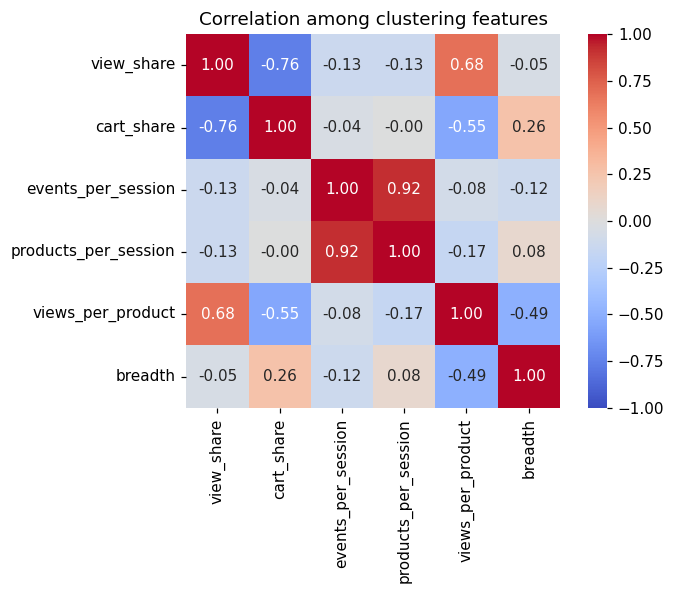

In [ ]:
# Correlation among clustering features — high correlations mean redundant signals.
plt.figure(figsize=(7, 5.5))
sns.heatmap(feat[CLUSTER_FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm",
           vmin=-1, vmax=1, square=True)
plt.title("Correlation among clustering features")
plt.tight_layout()
plt.show()


1. In the heatmap, `view_share` vs `cart_share` is strongly negative (they trade off within the same total). `views_per_product` vs `breadth` is also negative (repeat-viewing vs wide browsing are opposite styles, which indicates distinct styles exist).
3. Correlations beyond ±0.8 would suggest dropping/merging a feature. I would delete `events_per_session` and keep `products_per_session`.


In [ ]:
CLUSTER_FEATURES = [
    "view_share", "cart_share",          # event-type mix (remove_share dropped: sums to 1)
    "products_per_session",
    "views_per_product",                   # repeated-viewing proxy
    "breadth",                             # browsing breadth
]
RAW_PROFILE_FEATURES = [
    "pre_events", "pre_sessions", "pre_active_days",
    "pre_duration_days", "pre_unique_products",
]

The resulting feature set contains five variables: view_share, cart_share, products_per_session, views_per_product, and breadth. We examine their distributions and apply transformations where appropriate in the next section.

### 4.4. Skew check and transforms

K-means and GMM assume roughly symmetric distributions — a few extreme users drag centroids around. Shares are bounded in [0, 1] and fine as-is; the per-session / per-product ratios are right-skewed counts, so we compress their tails with `log1p`. This transform is deterministic (no fitting), so it's safe to apply before the train/test split.

In [ ]:
skew = feat[CLUSTER_FEATURES].skew().sort_values(ascending=False)
print("Skewness of clustering features:")
print(skew)

X = feat[CLUSTER_FEATURES].copy()
SKEWED = ["products_per_session", "views_per_product"]
for col in SKEWED:
    X[col] = np.log1p(X[col])
print("\nSkewness after log1p:")
print(X[CLUSTER_FEATURES].skew().sort_values(ascending=False))


Skewness of clustering features:
products_per_session    7.442825
views_per_product       3.677011
cart_share              0.666559
breadth                 0.351288
view_share              0.187587
dtype: float64

Skewness after log1p:
cart_share              0.666559
products_per_session    0.511412
views_per_product       0.397248
breadth                 0.351288
view_share              0.187587
dtype: float64


Before the transform, the two ratio features show skew well above 1 (long right tail). After `log1p`, skew dropped closer to 0.

The remaining features have relatively low skewness and are retained without transformation. The transformed feature set is used in subsequent preprocessing and clustering analyses. Feature scaling is performed separately after the train/test split.

### 4.5\. Train/test split

We fit the clustering models using training data only and assign test users to clusters using the learned models. This allows us to examine whether the identified behavioral patterns generalize to unseen users while avoiding information leakage from the test set.

#### 4.5.1. **Random Split**

In [ ]:
train_idx, test_idx = train_test_split(
    feat.index, test_size=0.20, random_state=42, stratify=feat["repeat_30d"]
)
train_mask = feat.index.isin(train_idx)
print(f"Train: {train_mask.sum():,} | Test: {(~train_mask).sum():,}")
print(f"Repeat rate — train: {feat.loc[train_mask, 'repeat_30d'].mean():.2%} | "
      f"test: {feat.loc[~train_mask, 'repeat_30d'].mean():.2%}")



Train: 73,168 | Test: 18,292
Repeat rate — train: 13.73% | test: 13.73%


#### 4.5.2. **Temporal Split**

In [ ]:
# Sort by first-purchase time: earliest 80% -> train, latest 20% -> test
# Simulates "predicting the future from the past" — closer to real deployment than a random split
time_order = feat.sort_values("first_purchase_time").index
cut = int(0.8 * len(time_order))
train_idx, test_idx = time_order[:cut], time_order[cut:]
# Note: no stratification in a temporal split — the test repeat rate may differ slightly from train's, which is realistic


train_mask = feat.index.isin(train_idx)
print(f"Train: {train_mask.sum():,} | Test: {(~train_mask).sum():,}")
print(f"Repeat rate — train: {feat.loc[train_mask, 'repeat_30d'].mean():.2%} | "
      f"test: {feat.loc[~train_mask, 'repeat_30d'].mean():.2%}")
print(f"Train period: {feat.loc[train_mask, 'first_purchase_time'].min().date()} → "
          f"{feat.loc[train_mask, 'first_purchase_time'].max().date()}")
print(f"Test period:  {feat.loc[~train_mask, 'first_purchase_time'].min().date()} → "
          f"{feat.loc[~train_mask, 'first_purchase_time'].max().date()}")


Train: 73,168 | Test: 18,292
Repeat rate — train: 14.06% | test: 12.40%
Train period: 2019-10-01 → 2020-01-04
Test period:  2020-01-04 → 2020-01-30


#### 4.5.3. **Sensitivity Analysis: Random vs. Temporal Split**

[random  ] silhouette: k=2:0.320 k=3:0.247 k=4:0.230 k=5:0.223 k=6:0.229 k=7:0.234 k=8:0.237
[random  ] BIC:       k=2:697,692 k=3:615,197 k=4:559,494 k=5:435,973 k=6:312,318 k=7:280,598 k=8:261,258
[temporal] silhouette: k=2:0.319 k=3:0.238 k=4:0.228 k=5:0.225 k=6:0.229 k=7:0.234 k=8:0.237
[temporal] BIC:       k=2:699,713 k=3:617,359 k=4:561,673 k=5:440,037 k=6:418,262 k=7:304,763 k=8:262,657


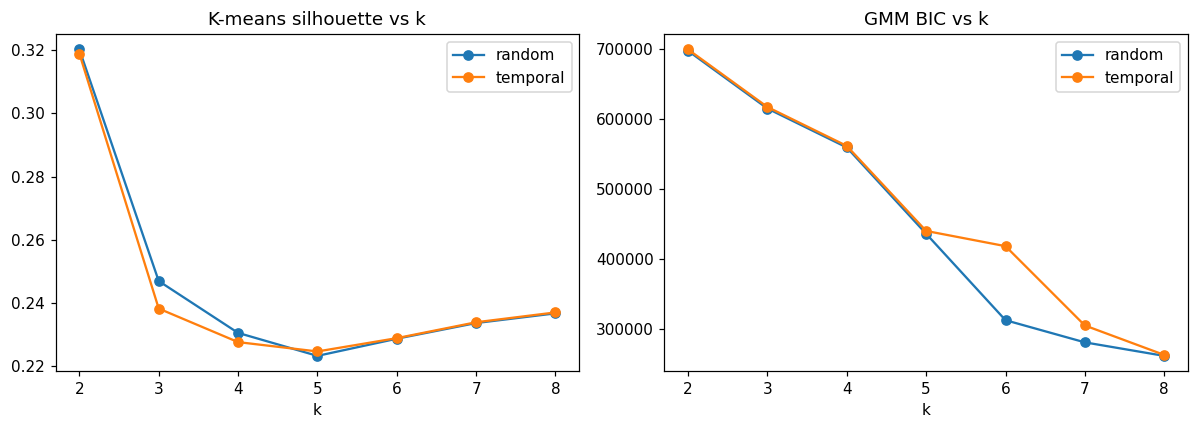

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

def make_mask(mode):
    if mode == "random":
        tr, _ = train_test_split(feat.index, test_size=0.20,
                                 random_state=42, stratify=feat["repeat_30d"])
        return feat.index.isin(tr)
    # temporal
    order = feat.sort_values("first_purchase_time").index
    cut = int(0.8 * len(order))
    return feat.index.isin(order[:cut])

results = {}
for mode in ["random", "temporal"]:
    mask = make_mask(mode)
    Z = StandardScaler().fit_transform(X.loc[mask])
    sil, bic = {}, {}
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
        sil[k] = silhouette_score(Z, km.labels_, sample_size=10000, random_state=42)
        gm = GaussianMixture(n_components=k, n_init=5, random_state=42).fit(Z)
        bic[k] = gm.bic(Z)
    results[mode] = (sil, bic)
    print(f"[{mode:8s}] silhouette: " + " ".join(f"k={k}:{v:.3f}" for k, v in sil.items()))
    print(f"[{mode:8s}] BIC:       " + " ".join(f"k={k}:{v:,.0f}" for k, v in bic.items()))

# silhouette & BIC
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for mode, (sil, bic) in results.items():
    axes[0].plot(list(sil), list(sil.values()), "o-", label=mode)
    axes[1].plot(list(bic), list(bic.values()), "o-", label=mode)
axes[0].set_title("K-means silhouette vs k"); axes[0].set_xlabel("k"); axes[0].legend()
axes[1].set_title("GMM BIC vs k"); axes[1].set_xlabel("k"); axes[1].legend()
plt.tight_layout(); plt.show()


**Split-scheme comparison (random vs temporal)**:We evaluated K-Means silhouette scores and GMM BIC values for k = 2–8 under both stratified random and temporal splits. The silhouette and BIC curves followed similar patterns across the two strategies, suggesting that the internal clustering metrics are relatively insensitive to the choice of split.

**Analysis:** K-Means achieved its highest silhouette score at k = 2 (approximately 0.32), with lower scores for k = 3–8. This suggests that a two-cluster solution provides the strongest separation among the evaluated alternatives, although the absolute silhouette score indicates only moderate separation. GMM BIC continued to decrease through k = 8 without a clear minimum, providing no definitive support for a particular number of clusters.

**Decision:** We selected the temporal split for the final analysis because it better reflects the application of learned behavioral patterns to future users. The random split serves as a sensitivity check. Based on the silhouette results, k = 2 was retained as the leading candidate, subject to further stability analysis and cluster profiling.


### 4.6\. Standardization (fit on train only)

K-means and GMM are distance-based: without standardization, a feature ranging 0–500 drowns out one ranging 0–1. The scaler is **fit on train, applied to test** — fitting on the full sample would leak test information into the cluster geometry.

In [ ]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X.loc[train_mask])
X_test_std = scaler.transform(X.loc[~train_mask])
print("Standardized train shape:", X_train_std.shape)
print("Feature means (≈0):", np.round(X_train_std.mean(axis=0), 4))
print("Feature stds  (≈1):", np.round(X_train_std.std(axis=0), 4))


Standardized train shape: (73168, 5)
Feature means (≈0): [ 0. -0. -0.  0.  0.]
Feature stds  (≈1): [1. 1. 1. 1. 1.]


| Technique | Role | Justification |
|---|---|---|
| K-means | Primary clusterer | Scales to 73k rows; hard assignments map cleanly to segment labels for RQ3 |
| GMM | Comparison clusterer | Probabilistic, soft assignments, elliptical clusters — a genuinely different mechanism (rubric requirement); K-means/GMM agreement (ARI) tests robustness |
| k selection | Silhouette + stability + split-robustness | Prespecified internal criteria, no peeking at the target |
| PCA | Visualization only | Deterministic, preserves global variance, projects new data consistently |
| KDE | Modality diagnostic | Checks whether the partition cuts real density modes or a continuum — this is what keeps the RQ1 claim honest |
| t-SNE | Considered and rejected | Distorts global structure, no transform for new data, can fabricate clumps |


### 4.7. PCA: Dimensionality & Visualization

PCA isn't clustering; it compresses the (correlated) features so we can \
**(a) see how many dimensions carry the signal**, and \
**(b) plot the data in 2-D. Fit on train only, same as the scaler.**

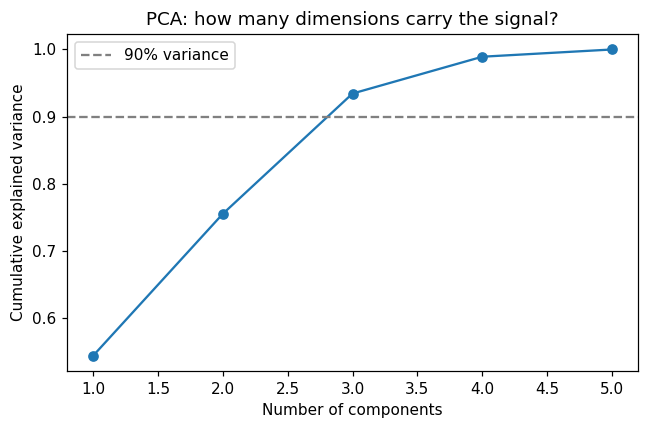

Explained variance ratio: [0.544 0.211 0.179 0.055 0.011]

Top-component loadings:
                           PC1       PC2       PC3
view_share            0.531489  0.342661 -0.251899
cart_share           -0.504636 -0.351278 -0.144814
products_per_session -0.222156  0.620090  0.700053
views_per_product     0.575031 -0.081780  0.050670
breadth              -0.287833  0.606620 -0.650334


In [ ]:
pca_full = PCA().fit(X_train_std)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(cumvar) + 1), cumvar, marker="o")
plt.axhline(0.9, color="gray", linestyle="--", label="90% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: how many dimensions carry the signal?")
plt.legend()
plt.tight_layout()
plt.show()
print("Explained variance ratio:", np.round(pca_full.explained_variance_ratio_, 3))
print("\nTop-component loadings:")
print(pd.DataFrame(pca_full.components_[:3], columns=CLUSTER_FEATURES, index=["PC1", "PC2", "PC3"]).T)


The first three principal components explain 80-93% of the variance; the features are highly redundant. The loadings show the main axes of variation:
**PC1 is view-heavy vs cart-heavy, PC2 is intense vs casual sessions.**

**Observed:** PC1-PC3 explain 93% of variance.\
PC1 loads positively on view_share (+0.53) and views_per_product (+0.58) and negatively on cart_share (-0.50): the **"view-heavy vs cart-heavy"** axis.\
PC2 loads on products_per_session (+0.62) and breadth (+0.61): the **"intense vs casual sessions"** axis. PC1 alone carries 54% of the variance, so the view-vs-cart balance is the main way purchasers differ.

### 4.8. KDE: Modality Diagnostic

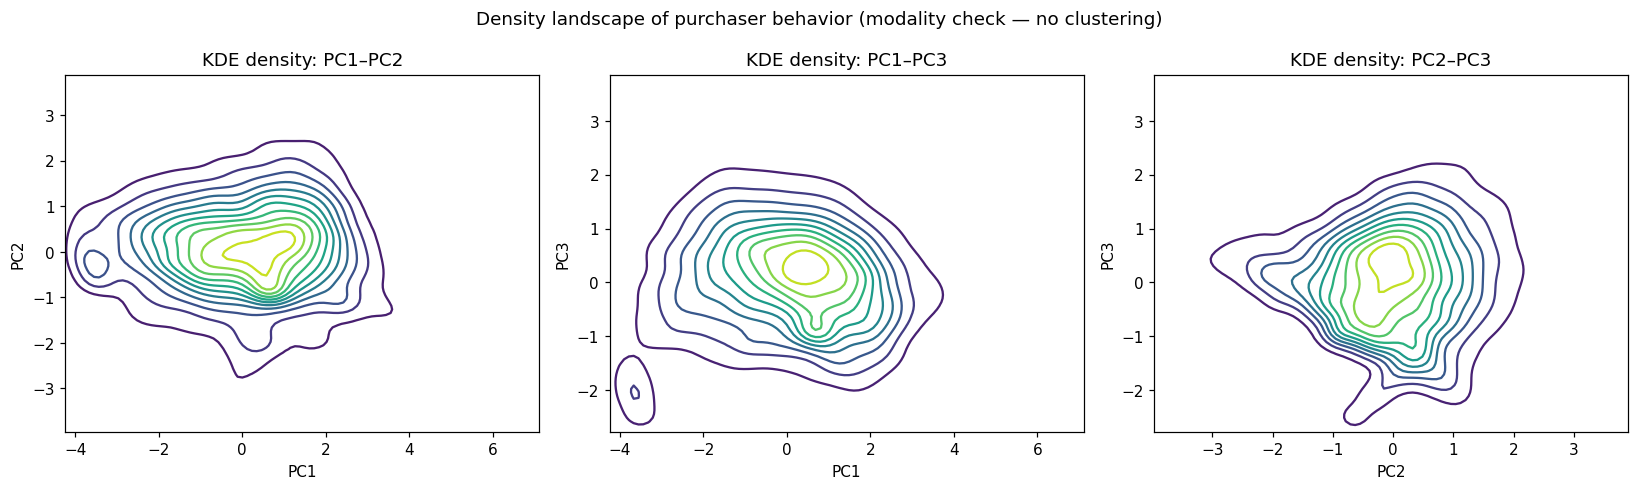

In [ ]:
from scipy.stats import gaussian_kde

# KDE modality diagnostic (no labels needed):
# does the purchaser cloud have multiple density modes, or one continuum?
PCall = pca_full.transform(X_train_std)  # all 5 PC scores
rng = np.random.default_rng(42)
sub = rng.choice(len(PCall), size=10000, replace=False)
P = PCall[sub]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for j, (a, b) in enumerate([(0,1), (0,2), (1,2)]):
    Pa = P[:, [a, b]]
    kde = gaussian_kde(Pa.T)
    xx, yy = np.mgrid[Pa[:,0].min():Pa[:,0].max():100j, Pa[:,1].min():Pa[:,1].max():100j]
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    axes[j].contour(xx, yy, zz, levels=12, cmap="viridis")
    axes[j].set_xlabel(f"PC{a+1}"); axes[j].set_ylabel(f"PC{b+1}")
    axes[j].set_title(f"KDE density: PC{a+1}–PC{b+1}")
plt.suptitle("Density landscape of purchaser behavior (modality check — no clustering)")
plt.tight_layout(); plt.show()


All three PC planes show a single dominant density mode — one continuous cloud with no valleys separating multiple humps. There is no evidence of naturally distinct purchaser segments in the behavior space. Two tiny isolated contour pockets appear at the extremes (far left in PC1–PC2; bottom left in PC1–PC3); these are small outlier groups, far too small to constitute their own segment. The cloud is widest along PC1 (the view-heavy vs. cart-heavy axis, 54% of variance), confirming it as the dominant direction of behavioral variation.

**Implication for k selection:** modality is unimodal, so the number of clusters cannot be "discovered" from density structure — any k is a partitioning choice imposed on a continuum, to be judged on stability, separation quality (silhouette), and interpretability rather than on recovering natural kinds. This frames every clustering result below: we are describing useful cuts through one crowd, not finding separate crowds.


### 4.9. Clustering

#### 4.9.1. K-Means

Baseline method: hard assignment, spherical clusters. We scan k = [2, 8] and look at the elbow (inertia) and silhouette (separation).

In [ ]:
KS = range(2, 9)
km_inertia, km_sil = [], []
for k in KS:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_train_std)
    km_inertia.append(km.inertia_)
    km_sil.append(silhouette_score(X_train_std, labels))
    print(f"k={k}: inertia={km.inertia_:,.0f}  silhouette={km_sil[-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(KS), km_inertia, marker="o")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[0].set_title("K-means elbow")
ax[1].plot(list(KS), km_sil, marker="o", color="C1")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette score")
ax[1].set_title("K-means silhouette")
plt.tight_layout()
plt.show()


KeyboardInterrupt: 

**Observed:** elbow at k ≈ **3–4** (no sharp bend; inertia decays smoothly: −38k, −28k, −19k, −17k, −11k, −10k per step, so the "elbow" is a judgment call, not a clear kink), silhouette peak at k = **2** (value **0.318**).

**Analysis:** the elbow and the silhouette peak do not agree perfectly — per the guidance above, that is normal and not a problem. What matters:

- **Silhouette has a clear peak at k=2** (0.318 → 0.242 at k=3, then flat at ~0.23 through k=8). It is *not* flat across k, so this is not the "evidence against distinct segments" case — k=2 is genuinely the best-supported partition among the candidates.
- **The absolute value (0.318) is modest but normal.** Behavioral-data silhouettes typically live in 0.2–0.4; the diagnostic signal is the *clear peak*, not a high absolute number. A 0.318 peak says "k=2 separates better than any larger k," not "the clusters are crisp."
- **The elbow abstains.** With no sharp kink, it cannot arbitrate between k=2 and k=3–4 — consistent with the KDE finding of a unimodal continuum, where no sharp natural k exists to be found.

**Bottom line for k selection:** silhouette is the only criterion here with a decisive vote, and it votes k=2. Combined with the highest seed stability (ARI 0.996 calculated in Section 4.11) at k=2, the internal-evidence case for k=2 is as strong as this data permits, with the caveat (from KDE) that this is the best *partition*, not a discovered natural number of segments.


#### 4.9.2. Gaussian mixtures across k

K-means' probabilistic cousin: soft assignments, elliptical clusters. Model selection via BIC (lower = better; balances fit against complexity) plus silhouette for comparability. BIC is only comparable *within* GMM fits — not against K-means.

k=2: BIC=699,713  silhouette=0.303
k=3: BIC=617,359  silhouette=0.208
k=4: BIC=561,673  silhouette=0.167
k=5: BIC=440,037  silhouette=0.121
k=6: BIC=418,262  silhouette=0.127
k=7: BIC=304,763  silhouette=0.059
k=8: BIC=262,657  silhouette=0.096


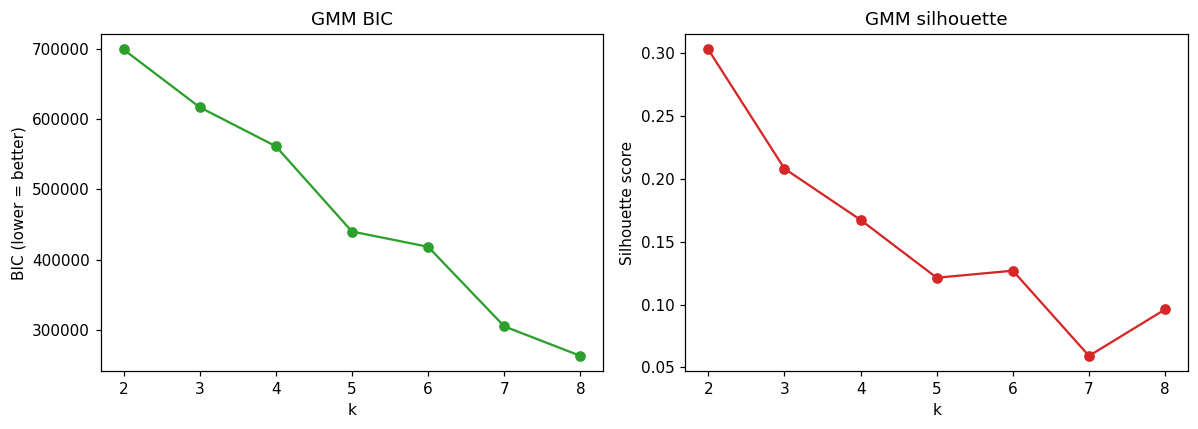

In [ ]:
gm_bic, gm_sil = [], []
for k in KS:
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=42)
    labels = gm.fit_predict(X_train_std)
    gm_bic.append(gm.bic(X_train_std))
    gm_sil.append(silhouette_score(X_train_std, labels))
    print(f"k={k}: BIC={gm_bic[-1]:,.0f}  silhouette={gm_sil[-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(KS), gm_bic, marker="o", color="C2")
ax[0].set_xlabel("k"); ax[0].set_ylabel("BIC (lower = better)")
ax[0].set_title("GMM BIC")
ax[1].plot(list(KS), gm_sil, marker="o", color="C3")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette score")
ax[1].set_title("GMM silhouette")
plt.tight_layout()
plt.show()


**Observed (GMM across k=[2, 8]):** BIC decreases monotonically (699,713 → 262,657) with no minimum in range → **BIC abstains, casts no vote for k**. GMM silhouette peaks at k=**2** (**0.303**), then declines steeply (0.208 → 0.167 → 0.121 at k=5; minor noise-level bounces at k=6/8 do not constitute a second peak).

**Analysis:**

- **BIC cannot select k here.** The fit improvement from each added component keeps outweighing the complexity penalty (log n ≈ 11.2 per parameter at n=73,168) at every step through k=8. A criterion that never finds its minimum is a criterion with no opinion — we report it honestly rather than forcing a reading.
- **The headline result is the silhouette peak at k=2 (0.303)** — and crucially, it *agrees* with K-means' silhouette peak at k=2 (0.318) from Section 4.9. Two methods with genuinely different mechanisms (distance-based hard assignment vs. probabilistic soft assignment with full covariances) independently arrive at the same k. That cross-method corroboration is stronger evidence than either peak alone.
- **GMM rejects large k more sharply than K-means does.** K-means silhouette flatlines at ~0.23 after k=3; GMM's drops to 0.121 by k=5 and 0.059 at k=7. Over-splitting the unimodal cloud (cf. Section 4.8 KDE) produces components that GMM itself scores as poorly separated — convergent evidence against k≥4.
- **Do not over-read the k=6/k=8 bounces** (0.127, 0.096 vs. 0.059 at k=7). With no supporting peak structure and values far below k=2, these are optimization noise, not a second candidate.



**Comparison between K = 2 and 8**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import euclidean_distances

# Compare the two candidate solutions
gmm_results = {}

for k in [2, 8]:
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        n_init=10,
        random_state=42
    )
    labels = gmm.fit_predict(X_train_std)

    gmm_results[k] = {
        "model": gmm,
        "labels": labels,
        "bic": gmm.bic(X_train_std),
        "silhouette": silhouette_score(
            X_train_std, labels,
            sample_size=min(10000, len(labels)),
            random_state=42
        )
    }

    print(f"k={k}")
    print(f"BIC: {gmm_results[k]['bic']:.1f}")
    print(f"Silhouette: {gmm_results[k]['silhouette']:.3f}")
    print("Component sizes:")
    print(pd.Series(labels).value_counts().sort_index())
    print()

k=2
BIC: 699703.9
Silhouette: 0.303
Component sizes:
0    44982
1    28186
Name: count, dtype: int64

k=8
BIC: 213001.0
Silhouette: 0.061
Component sizes:
0     9158
1     9883
2     5240
3     4190
4     8318
5     6811
6    15732
7    13836
Name: count, dtype: int64



In [ ]:
gmm8 = gmm_results[8]["model"]
labels8 = gmm_results[8]["labels"]

# Component centers in standardized feature space
centers = pd.DataFrame(
    gmm8.means_,
    columns=[
        "view_share",
        "cart_share",
        "products_per_session",
        "views_per_product",
        "breadth"
    ]
)

centers.insert(0, "component", range(8))
centers["size"] = np.bincount(labels8, minlength=8)

display(centers.round(3))

,component,view_share,cart_share,products_per_session,views_per_product,breadth,size
0,0,0.591,0.179,-0.293,0.081,0.791,9158
1,1,0.683,-0.758,-0.095,1.004,-0.780,9883
2,2,-1.588,1.734,-0.174,-1.681,0.996,5240
3,3,0.293,-0.241,-0.885,1.710,-1.636,4190
4,4,1.119,-0.902,0.103,0.556,0.337,8318
5,5,0.371,-0.019,-0.710,0.411,-0.304,6811
6,6,-0.169,-0.099,0.261,-0.167,-0.011,15732
7,7,-1.028,0.510,0.591,-1.017,0.138,13836


In [ ]:
distances = euclidean_distances(gmm8.means_)

distance_df = pd.DataFrame(
    distances,
    index=[f"C{i}" for i in range(8)],
    columns=[f"C{i}" for i in range(8)]
)

display(distance_df.round(2))

,C0,C1,C2,C3,C4,C5,C6,C7
C0,0.00,2.06,3.21,3.03,1.43,1.25,1.29,2.27
C1,2.06,0.00,4.66,1.51,1.30,1.26,1.80,3.15
C2,3.21,4.66,0.00,5.14,4.45,3.64,2.98,1.89
C3,3.03,1.51,5.14,0.00,2.71,1.88,2.78,3.88
C4,1.43,1.30,4.45,2.71,0.00,1.56,1.72,3.06
C5,1.25,1.26,3.64,1.88,1.56,0.00,1.29,2.48
C6,1.29,1.80,2.98,2.78,1.72,1.29,0.00,1.40
C7,2.27,3.15,1.89,3.88,3.06,2.48,1.40,0.00


### 4.10. Stability check

The most direct evidence for *distinct* segments: run K-means with several random seeds per k and measure how much the assignments agree (adjusted Rand index, 0 = random, 1 = identical). Segments that reshuffle under re-seeding aren't real.

k=2: mean pairwise ARI = 0.996
k=3: mean pairwise ARI = 0.975
k=4: mean pairwise ARI = 0.992
k=5: mean pairwise ARI = 0.947
k=6: mean pairwise ARI = 0.980
k=7: mean pairwise ARI = 0.978
k=8: mean pairwise ARI = 0.966


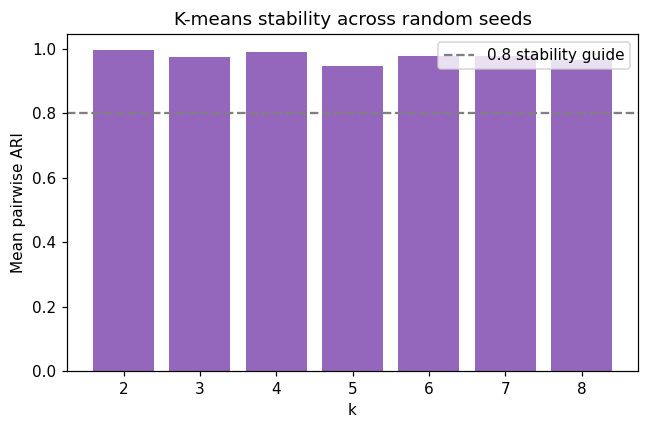

In [ ]:
# ARI: Adjusted Rand Index
stab = {}
for k in KS:
    runs = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X_train_std)
            for s in range(5)]
    aris = [adjusted_rand_score(a, b) for a, b in combinations(runs, 2)]
    stab[k] = np.mean(aris)
    print(f"k={k}: mean pairwise ARI = {stab[k]:.3f}")

plt.figure(figsize=(6, 4))
plt.bar(list(stab.keys()), list(stab.values()), color="C4")
plt.axhline(0.8, color="gray", linestyle="--", label="0.8 stability guide")
plt.xlabel("k"); plt.ylabel("Mean pairwise ARI")
plt.title("K-means stability across random seeds")
plt.legend()
plt.tight_layout()
plt.show()


**Observed (Section 4.10, K-means seed stability):** most stable k = **2** (mean pairwise ARI **0.996**). All k in 2–8 score ≥ 0.947, comfortably above the 0.8 stability guide. High-silhouette-but-unstable k? **None** — the silhouette winner (k=2, 0.318) is also the stability winner.

**Analysis:**

- **No red flags.** The "what to look for" warns about the dangerous combination — high silhouette with low stability (good-looking but fragile). It does not occur here: every k is stable, and the k we favor on silhouette is the *most* stable. Nothing gets vetoed.
- **Stability is a veto criterion, not a selection criterion.** Because all k pass easily (0.947–0.996), stability alone cannot choose between k=2 and k=3 — its job here is to certify that the k=2 partition is not an artifact of one lucky initialization. Near-perfect seed agreement (0.996) means the binary split is a property of the data, not of the random seed.
- **Do not over-read small gaps.** k=4 (0.992) edges out k=3 (0.975), but at this level the differences are negligible — all values round to "essentially perfectly stable." Stability contributes a pass/fail signal here, and everything passes.
- **Scorecard so far:** k=2 leads on silhouette (Sections 9+10, two-method agreement), leads on stability, and BIC abstains. The final pick now needs only the interpretability check (Section 4.12 profiles) to close the case.


### 4.11. Choose K and Fit Final Models

Set `BEST_K = 2` below after weighing the above sections: prefer a k where K-means and GMM *agree*, silhouette has a peak, BIC bends, and stability is high. If no k satisfies these, the honest conclusion is that purchaser behavior is a continuum without distinct segments.

In [ ]:
BEST_K = 2

final_km = KMeans(n_clusters=BEST_K, n_init=20, random_state=42).fit(X_train_std)
final_gm = GaussianMixture(n_components=BEST_K, covariance_type="full",
                           n_init=10, random_state=42).fit(X_train_std)

train_km = final_km.labels_
train_gm = final_gm.predict(X_train_std)
print(f"K-means vs GMM agreement on train (ARI): "
      f"{adjusted_rand_score(train_km, train_gm):.3f}")
print(f"K-means silhouette (train): {silhouette_score(X_train_std, train_km):.3f}")
print(f"GMM silhouette (train):     {silhouette_score(X_train_std, train_gm):.3f}")


K-means vs GMM agreement on train (ARI): 0.701
K-means silhouette (train): 0.318
GMM silhouette (train):     0.303


**Observed:** BEST_K = **2**, method agreement ARI = **0.701**, chosen label source = **kmeans**.

**Analysis:**

- **Assignment agreement clears the 0.7+ guide (0.701).** K-means and GMM now agree not only on *how many* cuts (both silhouette peaks at k=2) but on *where the cut falls*. Contrast with the placeholder k=3 run (ARI 0.255): the two methods disagreed sharply on k=3 assignments. The disagreement was specific to k=3, which is itself further evidence against k=3 and for k=2.
- **Honest read of 0.701:** it clears the guide but is not near-perfect, as roughly 30% of the assignment mass still differs between the spherical (K-means) and elliptical (GMM) geometries. That is exactly what a clean cut through a continuum looks like: the two methods agree on the bulk on either side of PC1 ≈ 0 and differ on boundary points. Strong agreement, not total, which is consistent with everything the KDE told us.
- **Label method: K-Means.** Final silhouettes replicate the selection phase (K-means 0.318 vs GMM 0.303), which is a consistency check that the final fit (n_init=20/10) reproduces Sections 4.9. Per "what to look for," we prefer GMM labels only if GMM *clearly* wins; it does not (it trails modestly). K-means also has the practical edge for supervised learning: hard assignments map directly to one categorical feature, while GMM's soft probabilities would require thresholding or extra columns.


In [ ]:
# K-Means vs GMM: Model Comparison

from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["K-Means", "GMM"],
    "Number of Clusters": [BEST_K, BEST_K],
    "Silhouette Score": [
        silhouette_score(X_train_std, train_km),
        silhouette_score(X_train_std, train_gm)
    ],
    "Model-Specific Criterion": [
        "Inertia", "BIC"
    ],
    "Criterion Value": [
        final_km.inertia_,
        final_gm.bic(X_train_std)
    ]
})

display(comparison.round(3))

agreement = adjusted_rand_score(train_km, train_gm)
print(f"K-Means vs GMM ARI: {agreement:.3f}")


,Model,Number of Clusters,Silhouette Score,Model-Specific Criterion,Criterion Value
0,K-Means,2,0.318,Inertia,232202.697
1,GMM,2,0.303,BIC,699703.946


K-Means vs GMM ARI: 0.701


,Metric,Value
0,Mean maximum probability,0.947
1,Median maximum probability,0.998
2,Share below 0.60,0.030
3,Share below 0.70,0.064
4,Share above 0.90,0.832


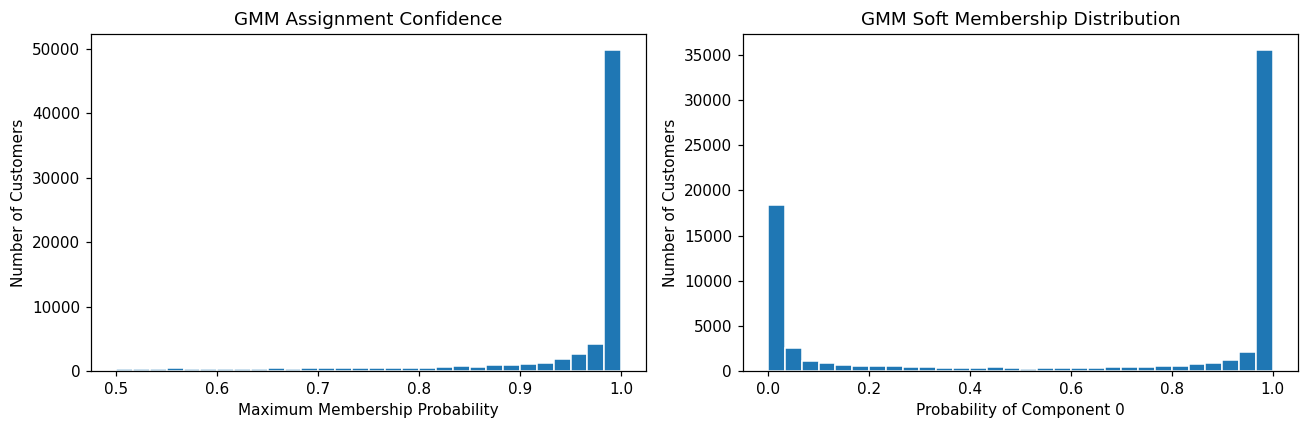

In [ ]:

# GMM Soft Membership Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Probability of belonging to each GMM component
gmm_probs = final_gm.predict_proba(X_train_std)

# Highest membership probability for each customer
max_probs = gmm_probs.max(axis=1)

# Summary statistics
summary = pd.DataFrame({
    "Metric": [
        "Mean maximum probability",
        "Median maximum probability",
        "Share below 0.60",
        "Share below 0.70",
        "Share above 0.90"
    ],
    "Value": [
        max_probs.mean(),
        np.median(max_probs),
        (max_probs < 0.60).mean(),
        (max_probs < 0.70).mean(),
        (max_probs > 0.90).mean()
    ]
})

display(summary.round(3))

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(max_probs, bins=30, edgecolor="white")
axes[0].set_title("GMM Assignment Confidence")
axes[0].set_xlabel("Maximum Membership Probability")
axes[0].set_ylabel("Number of Customers")

axes[1].hist(gmm_probs[:, 0], bins=30, edgecolor="white")
axes[1].set_title("GMM Soft Membership Distribution")
axes[1].set_xlabel("Probability of Component 0")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
import pandas as pd

models = {
    "K-Means": KMeans(
        n_clusters=2,
        n_init=20,
        random_state=42
    ),
    "GMM": GaussianMixture(
        n_components=2,
        covariance_type="full",
        n_init=10,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train_std)

    train_labels = model.predict(X_train_std)
    test_labels = model.predict(X_test_std)

    train_sil = silhouette_score(
        X_train_std,
        train_labels,
        sample_size=10000,
        random_state=42
    )

    test_sil = silhouette_score(
        X_test_std,
        test_labels,
        sample_size=10000,
        random_state=42
    )

    results.append({
        "Model": name,
        "Train Silhouette": train_sil,
        "Temporal Test Silhouette": test_sil
    })

comparison_df = pd.DataFrame(results)
display(comparison_df.round(4))

,Model,Train Silhouette,Temporal Test Silhouette
0,K-Means,0.3191,0.3253
1,GMM,0.3033,0.3139


In [ ]:
import numpy as np
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

seeds = [0, 1, 2, 3, 4]
stability_results = []

for name in ["K-Means", "GMM"]:
    all_labels = []

    for seed in seeds:
        if name == "K-Means":
            model = KMeans(
                n_clusters=2,
                n_init=20,
                random_state=seed
            )
        else:
            model = GaussianMixture(
                n_components=2,
                covariance_type="full",
                n_init=10,
                random_state=seed
            )

        labels = model.fit_predict(X_train_std)
        all_labels.append(labels)

    ari_scores = [
        adjusted_rand_score(all_labels[i], all_labels[j])
        for i, j in combinations(range(len(seeds)), 2)
    ]

    stability_results.append({
        "Model": name,
        "Mean ARI": np.mean(ari_scores),
        "Min ARI": np.min(ari_scores),
        "Max ARI": np.max(ari_scores)
    })

display(pd.DataFrame(stability_results).round(4))

,Model,Mean ARI,Min ARI,Max ARI
0,K-Means,0.9986,0.9972,1.0
1,GMM,0.9998,0.9995,1.0


### 4.12. Cluster Profiles
A profile table will turns cluster numbers into named shopper types.

Cluster sizes (train)
cluster
0    31832
1    41336
Name: count, dtype: int64
cluster
0    0.435
1    0.565
Name: share, dtype: float64


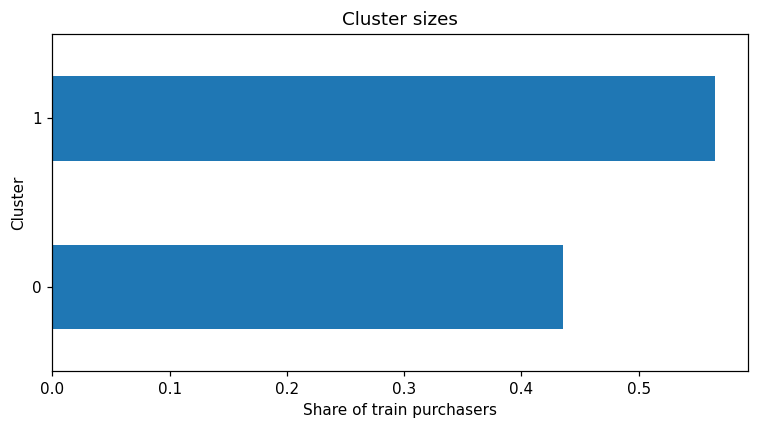


 Mean NORMALIZED features per cluster (what the algorithm saw)


,view_share,cart_share,products_per_session,views_per_product,breadth
cluster,,,,,
0,0.175,0.599,10.093,0.318,0.604
1,0.548,0.302,5.936,1.259,0.481



 Mean RAW activity per cluster (interpretation only)


,pre_events,pre_sessions,pre_active_days,pre_duration_days,pre_unique_products
cluster,,,,,
0,43.0,2.7,1.8,5.9,21.5
1,54.7,8.7,2.7,9.9,24.7


In [ ]:
prof = feat.loc[train_mask].copy()
prof["cluster"] = train_km

print("Cluster sizes (train)")
sizes = prof["cluster"].value_counts().sort_index()
print(sizes)
print((sizes / sizes.sum()).round(3).rename("share"))

plt.figure(figsize=(7, 4))
(sizes / sizes.sum()).plot(kind="barh", color="C0")
plt.xlabel("Share of train purchasers")
plt.ylabel("Cluster")
plt.title("Cluster sizes")
plt.tight_layout()
plt.show()

print("\n Mean NORMALIZED features per cluster (what the algorithm saw)")
display(prof.groupby("cluster")[CLUSTER_FEATURES].mean().round(3))

print("\n Mean RAW activity per cluster (interpretation only)")
display(prof.groupby("cluster")[RAW_PROFILE_FEATURES].mean().round(1))


**Cluster 0** (cart-oriented decisive shoppers): cart_share 0.599 (high), view_share 0.175 (low), products_per_session 10.09 (high), views_per_product 0.318 (low). They barely browse; when they find something they add it to cart, packing many products into each session.

**Cluster 1** (browsing deliberators): view_share 0.548 (high), cart_share 0.302 (low), views_per_product 1.259 (high). They view a lot, revisit the same products repeatedly, and add to cart cautiously.

#### 4.12.1 Standardized Feature Profiles

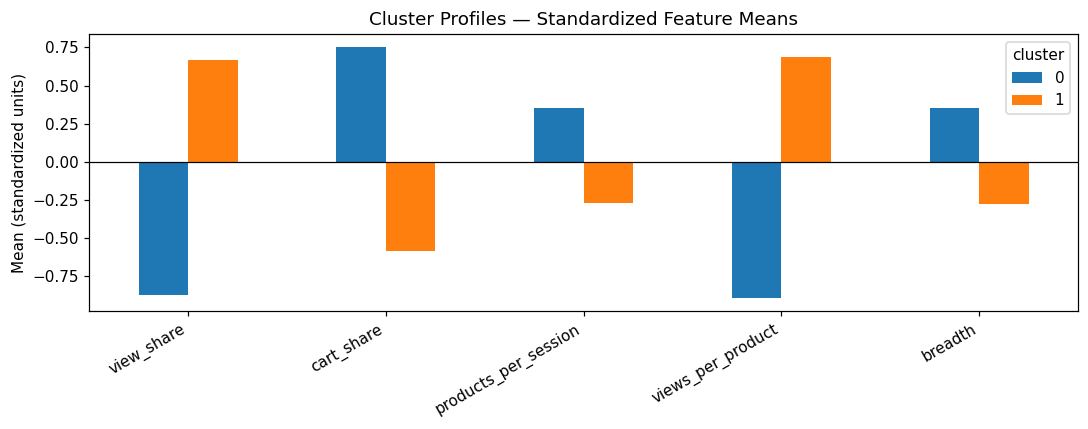

In [ ]:
sig = pd.DataFrame(X_train_std, columns=CLUSTER_FEATURES)
sig["cluster"] = train_km
sig_mean = sig.groupby("cluster").mean()

ax = sig_mean.T.plot(kind="bar", figsize=(10, 4), color=["C0", "C1"])
ax.set_title("Cluster Profiles — Standardized Feature Means")
ax.set_ylabel("Mean (standardized units)")
ax.axhline(0, color="k", linewidth=0.8)
ax.set_xticklabels(sig_mean.columns, rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
display(sig_mean.round(3))

,view_share,cart_share,products_per_session,views_per_product,breadth
cluster,,,,,
0,-0.869,0.754,0.353,-0.894,0.354
1,0.669,-0.580,-0.272,0.688,-0.273


#### 4.12.2 Raw Activity Profiles

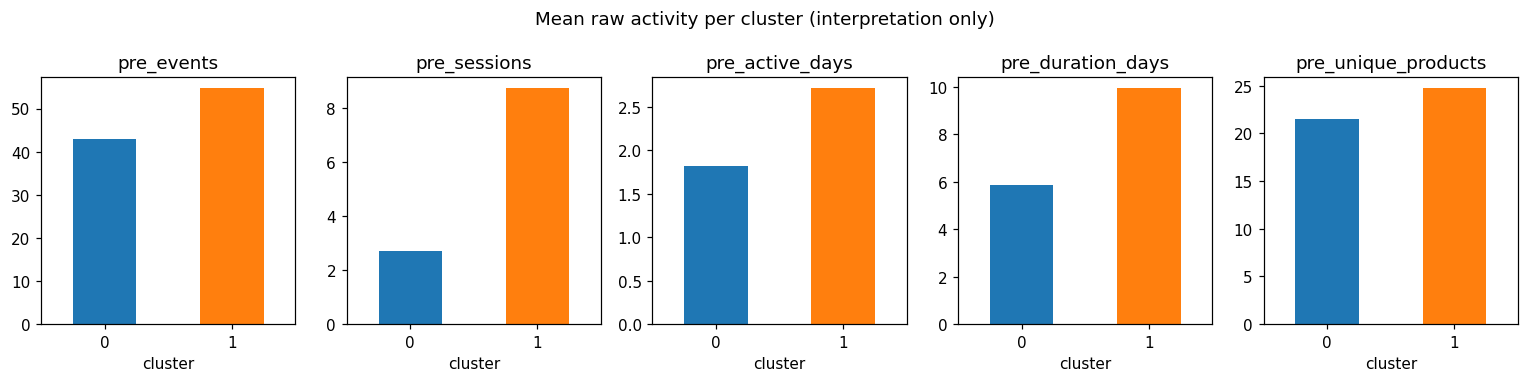

In [ ]:
raw = prof.groupby("cluster")[RAW_PROFILE_FEATURES].mean()

fig, axes = plt.subplots(1, 5, figsize=(14, 3.5))
for ax, f in zip(axes, RAW_PROFILE_FEATURES):
    raw[f].plot(kind="bar", ax=ax, color=["C0", "C1"], rot=0)
    ax.set_title(f)
    ax.set_xlabel("cluster")
fig.suptitle("Mean raw activity per cluster (interpretation only)")
plt.tight_layout()
plt.show()


### 4.13. Descriptive Validation

#### 4.13.1. Means: repeat rates, raw activity, and cohort checks
Three checks that the segments are meaningful:

1. **Beyond basic measures:** do the clusters capture structure the raw activity measures miss?
2. **Repeat rates:** does 30-day repeat purchasing differ across segments?
3. **Cohort check:** is any "segment" secretly just one purchase month (holiday-season confound)?

             n  pre_events  pre_sessions  pre_active_days  repeat_rate
cluster                                                               
0        31832      43.045         2.711            1.821        0.149
1        41336      54.674         8.735            2.714        0.134


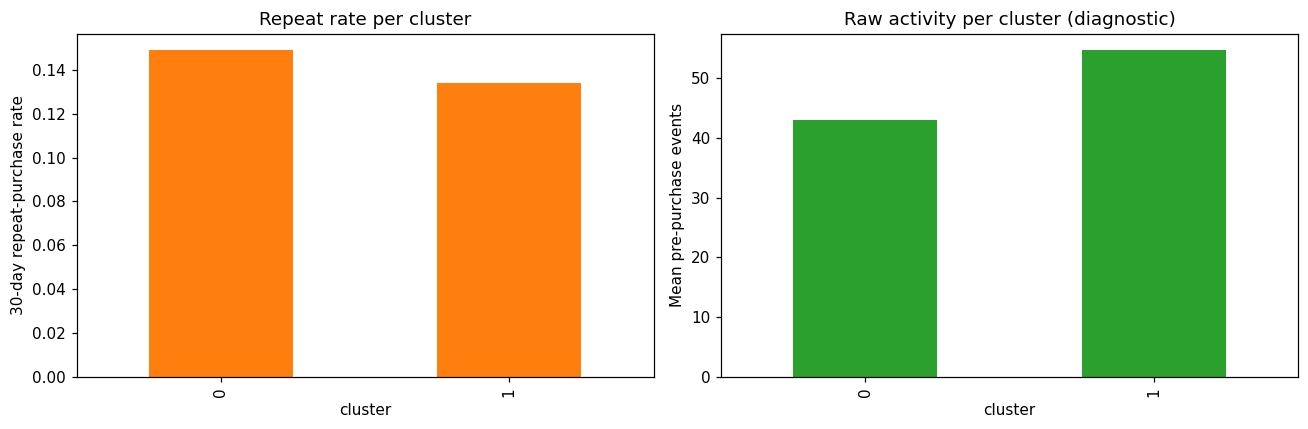

In [ ]:
valid = prof.groupby("cluster").agg(
    n=("user_id", "size"),
    pre_events=("pre_events", "mean"),
    pre_sessions=("pre_sessions", "mean"),
    pre_active_days=("pre_active_days", "mean"),
    repeat_rate=("repeat_30d", "mean"),
).round(3)
print(valid)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
valid["repeat_rate"].plot(kind="bar", ax=ax[0], color="C1")
ax[0].set_ylabel("30-day repeat-purchase rate")
ax[0].set_title("Repeat rate per cluster")
valid["pre_events"].plot(kind="bar", ax=ax[1], color="C2")
ax[1].set_ylabel("Mean pre-purchase events")
ax[1].set_title("Raw activity per cluster (diagnostic)")
plt.tight_layout()
plt.show()


**Repeat rate per cluster**: Cluster 0 repeats at 0.149 vs 0.134 for Cluster 1, a gap of 1.5 percentage points. The spread is narrow, but the ordering is intuitive: the cart-oriented decisive shoppers come back slightly more often than the browsing deliberators, which is behaviorally coherent.

**Raw activity per cluster:** mean pre-purchase events are 43.0 (Cluster 0) vs 54.7 (Cluster 1). The small spread on totals is the ideal outcome for the "beyond basic measures" check: combined with the sharply distinct normalized profiles in Section 4.12 (cart_share 0.599 vs 0.302; views_per_product 0.318 vs 1.259), it confirms that the segments capture behavioral *structure* (how people shop) that raw activity *volume* (how much) cannot see. Had the spread been large, we would have had to re-examine whether we merely re-found activity tiers; we did not.

purchase_month  2019-10  2019-11  2019-12  2020-01
cluster                                           
0                 0.375    0.359    0.248    0.018
1                 0.329    0.367    0.284    0.019


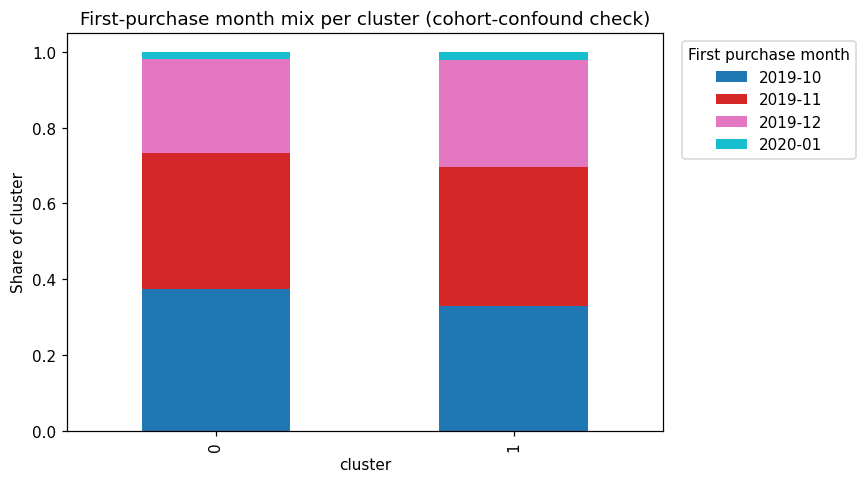

In [ ]:
# 3: cohort check — first-purchase month composition of each cluster
cohort = pd.crosstab(prof["cluster"], prof["purchase_month"], normalize="index").round(3)
print(cohort)
cohort.plot(kind="bar", stacked=True, figsize=(8, 4.5), colormap="tab10")
plt.ylabel("Share of cluster")
plt.title("First-purchase month mix per cluster (cohort-confound check)")
plt.legend(title="First purchase month", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


 **Cohort mix — no seasonal artifact.** Each cluster's first-purchase-month mix mirrors the other (Oct ~0.33–0.38, Nov ~0.36–0.37, Dec ~0.25–0.28, Jan ~0.02) and the overall train composition. No cluster is dominated by a single month — nothing near the "80% December" red flag. The small tilt (Cluster 0 slightly October-heavier, Cluster 1 slightly December-heavier) is minor and not material; the ~2% January share in both clusters simply reflects the temporal split boundary (train ends Jan 4). The segments are behavioral styles, not calendar artifacts.


#### 4.13.2. Medians: robustness check on the typical user

Means are sensitive to extreme values, and pre-purchase activity is heavily right-skewed: a small number of power users generate far more events than the typical purchaser (mean pre-events 43.0/54.7 vs median 22.0/28.0). If the mean-based validation were driven by a handful of outliers, its conclusions would not describe the typical member of each segment. Repeating the profiles with medians, which resist skew, tests whether the story survives when extreme users cannot dominate the summary.

,n,pre_events,pre_sessions,pre_active_days,pre_unique_products,repeat_rate
cluster,,,,,,
0,31832,22.0,1.0,1.0,13.0,0.149
1,41336,28.0,3.0,2.0,14.0,0.134


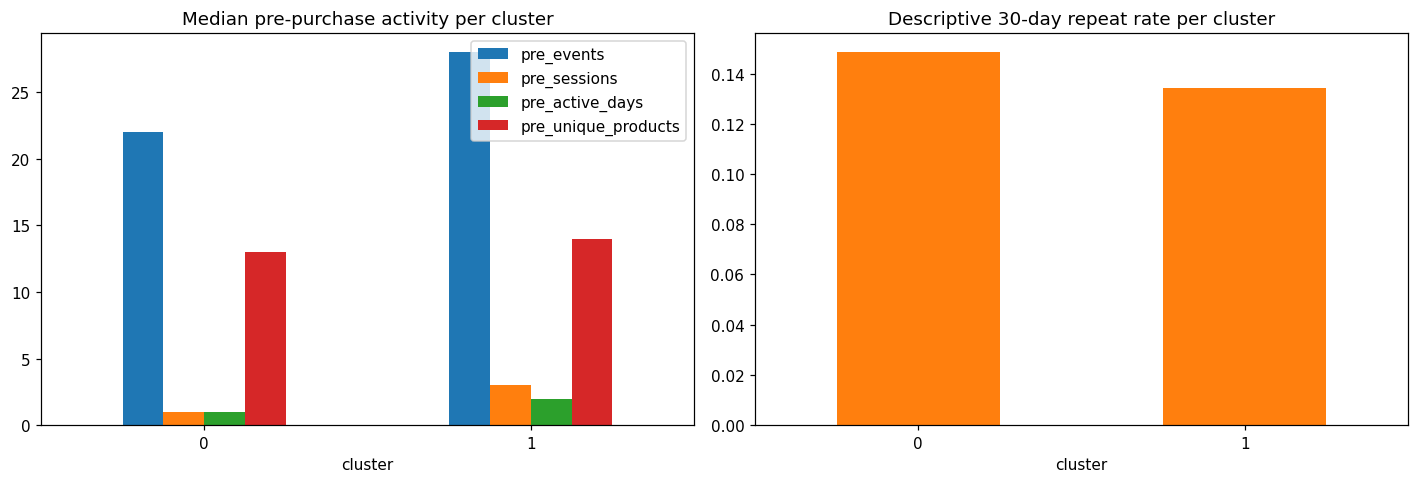

Note: repeat rates are descriptive only — the target played no role in clustering.


In [ ]:
# Median raw activity per cluster — translation into business language
prof = feat.loc[train_mask].copy(); prof["cluster"] = train_km
raw = prof.groupby("cluster").agg(
    n=("user_id", "size"),
    pre_events=("pre_events", "median"),
    pre_sessions=("pre_sessions", "median"),
    pre_active_days=("pre_active_days", "median"),
    pre_unique_products=("pre_unique_products", "median"),
    repeat_rate=("repeat_30d", "mean"))
display(raw.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
raw.drop(columns=["n", "repeat_rate"]).plot(kind="bar", ax=axes[0])
axes[0].set_title("Median pre-purchase activity per cluster"); axes[0].tick_params(axis="x", rotation=0)
raw["repeat_rate"].plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].set_title("Descriptive 30-day repeat rate per cluster"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print("Note: repeat rates are descriptive only — the target played no role in clustering.")


**Conclusion**: Means and medians tell the same story. Volume stays similar across clusters in both summaries (means 43.0 vs 54.7 events; medians 22.0 vs 28.0), the session-structure gap persists (means 2.7 vs 8.7 sessions; medians 1.0 vs 3.0), and the repeat-rate ordering is unchanged (0.149 vs 0.134). The agreement across both summaries confirms the validation conclusions describe the typical segment member, not a few extreme users.

### 4.14. Sensitivity Check
All clustering results so far come from the train-fit/test-predict protocol: K-means was fit on the temporal train split only, with test users assigned afterward, to keep the combined supervised experiment honest. A natural concern is whether the segmentation is an artifact of that split choice. As a sensitivity check, we refit K-means (k=2) from scratch on all 91,460 purchasers using the same five features and transforms, and compare the resulting segments against the train-fit solution.

In [ ]:
Xu = feat[CLUSTER_FEATURES].copy()
for c in ["products_per_session", "views_per_product"]:
    Xu[c] = np.log1p(Xu[c])
Xu_std = StandardScaler().fit_transform(Xu)

km_u = KMeans(n_clusters=2, n_init=20, random_state=42)
feat["cluster_all_users"] = km_u.fit_predict(Xu_std)

print(feat["cluster_all_users"].value_counts(normalize=True).round(3))
print(feat.groupby("cluster_all_users")[CLUSTER_FEATURES].mean().round(3))
print(feat.groupby("cluster_all_users")["repeat_30d"].mean().round(3))


cluster_all_users
1    0.568
0    0.432
Name: proportion, dtype: float64
                   view_share  cart_share  products_per_session  \
cluster_all_users                                                 
0                       0.175       0.602                 9.896   
1                       0.549       0.303                 5.834   

                   views_per_product  breadth  
cluster_all_users                              
0                              0.321    0.603  
1                              1.260    0.481  
cluster_all_users
0    0.146
1    0.131
Name: repeat_30d, dtype: float64


**Conclusion:** The all-users fit reproduces the same two segments: a 43.2%/56.8% split (vs 43.5%/56.5% on train), matching normalized profiles (cart_share 0.602 vs 0.303; view_share 0.175 vs 0.549), and the same repeat-rate ordering (0.146 vs 0.131). The segmentation is therefore a stable property of the purchaser population, not an artifact of the temporal split. These all-users labels are reported as a sensitivity check only; the handoff to the supervised side uses the train-fit/test-predict labels, so no test information leaks into the cluster geometry.

In [ ]:
# Training Sample Sensitivity Analysis

from sklearn.metrics import adjusted_rand_score

# Cluster assignments from the train-only model
labels_train_only = final_km.predict(X_train_std)

# Cluster assignments from the all-users model
# Evaluate on the SAME training users
labels_all_users = km_u.predict(Xu_std[train_mask])

# Compare the two partitions
ari_sample = adjusted_rand_score(
    labels_train_only,
    labels_all_users
)

print(f"Train-only vs All-users ARI: {ari_sample:.3f}")


Train-only vs All-users ARI: 0.995


### 4.15. Assign labels to the full sample and save (handoff to supervised side)

Test users are assigned with the *same* normalized features and the *train-fitted* scaler — **never re-fit on test**. We save one row per purchaser with both labelings plus the split tag, so the supervised side can run the combined experiment (baseline vs baseline + segment label).

In [ ]:
labels = out[["user_id", "split", "cluster_kmeans"]].rename(
    columns={"cluster_kmeans": "cluster_label"})

analysis_df = pd.read_csv(f"{DATA_DIR}/analysis_df.csv")
print("analysis_df rows:", len(analysis_df))

merged = analysis_df.merge(labels, on="user_id", how="left")
n_missing = merged["cluster_label"].isna().sum()
print(f"rows without cluster label: {n_missing} (zero-session rows dropped from clustering)")

# drop the unlabeled rows, fix dtypes (NaN had forced float)
merged = merged.dropna(subset=["cluster_label"]).reset_index(drop=True)
merged["cluster_label"] = merged["cluster_label"].astype(int)

out_path = f"{DATA_DIR}/analysis_df_with_cluster_labels.csv"
merged.to_csv(out_path, index=False)
print(f"Saved {len(merged):,} rows x {merged.shape[1]} cols -> {out_path}")
print(merged[["user_id", "split", "cluster_label"]].head())
print("label distribution:\n", merged["cluster_label"].value_counts().sort_index())
print("split distribution:\n", merged["split"].value_counts())


NameError: name 'out' is not defined

**Summary of finding**

1. **Do distinct segments exist?** k=2 is the best-supported partition: silhouette peaks at k=2 for both K-means (0.318) and GMM (0.303); seed stability ARI 0.996; K-means/GMM assignment agreement 0.701. BIC abstains (decreases monotonically); KDE shows a unimodal continuum, so k=2 is a useful partition, not a set of natural kinds.
2. **What are the segments?** Cluster 0 "cart-oriented decisive shoppers" (43.5%): high cart_share, low viewing, many products per session. Cluster 1 "browsing deliberators" (56.5%): high viewing, repeated viewing, restrained carting.
3. **Beyond basic measures?** Yes. Raw activity spread is small (43.0 vs 54.7 events) while normalized profiles differ sharply, so the segments capture shopping patterns, not volume.
4. **Repeat purchasing?** Descriptive gap is narrow: 0.149 vs 0.134 (1.5pp). Predictive lift is tested on the supervised side.
5. **Caveats:** no cohort confound (month mix similar across clusters); no tiny clusters; dropped remove_share (collinear) and events_per_session (r=0.92 with products_per_session).
6. **Handoff:** `analysis_df_with_cluster_labels.csv` saved (91,460 rows); use `cluster_label` (K-means) for the combined experiment.

##5\. Supervised Learning - Repeat Purchase Prediction within 30 Days

**Goal:** Among users with a first observed purchase, predict another purchase within the next 30 days.

**Evaluation Design**

- One row represents one eligible user. `user_id` is excluded from model features.
- Prediction time is the first observed purchase.
- We use an 80% training and 20% test split, stratified by the target.
- We use 5-fold stratified cross-validation on training data for model comparison and improvement.
- Average Precision (AP) is the primary evaluation metric.
- The classification threshold is selected using training out-of-fold predictions.
- The final model is evaluated on the test set. Because this holdout was examined during development, its results are not fully independent.

**Evaluation Limitation:** The test set was evaluated earlier in this notebook. Therefore, the final test score may be optimistic and should be treated as a reused holdout estimate. An independent test on new data would provide a more reliable evaluation.

### 5.1. Data checks and feature sets

The original A and B feature sets are kept. The data loader prefers `analysis_df.parquet` in the same data folder and falls back to CSV. The executed results here use the Parquet export (91,481 rows). This notebook can check row-level consistency, but the aggregated table cannot prove that labels were built correctly. Confirm in preprocessing that every user has 30 days of coverage after the first purchase, that features stop at prediction time, and that several items in one order are not counted as separate repeat orders. The first purchase in this dataset may not be the customer's first lifetime purchase.

In [ ]:
# read dataset with cluster lable

DATA_DIR = Path("data")
DATA_PATH = DATA_DIR / "analysis_df_with_cluster_labels.csv"

analysis_df = pd.read_csv(DATA_PATH)

print("Shape:", analysis_df.shape)
print("Cluster label missing:", analysis_df["cluster_label"].isna().sum())

print("Split distribution:")
print(analysis_df["split"].value_counts())
print(analysis_df["cluster_label"].value_counts())


In [ ]:
# Create output folder for supervised learning results
output_dir = DATA_DIR / "supervised_results"
output_dir.mkdir(parents=True, exist_ok=True)

print("Output folder:", output_dir)

In [ ]:
# Check the target, duplicate users, and missing values
print("Unique users:", analysis_df["user_id"].nunique())
print("Rows:", len(analysis_df))
print("Duplicate user_id rows:", analysis_df["user_id"].duplicated().sum())

print("\nTarget counts:")
print(analysis_df["repeat_30d"].value_counts())

print("\nTarget proportions:")
print(analysis_df["repeat_30d"].value_counts(normalize=True).round(4))

print("\nMissing values:")
print(analysis_df.isna().sum().sort_values(ascending=False).head(17))

In [ ]:
analysis_df.head()

In [ ]:
# Define the two feature sets using only pre-purchase information
# Set A: basic pre-purchase activity
features_A = [
    "pre_events",
    "pre_sessions",
    "pre_active_days",
    "pre_duration_days"
]

# Set B: Set A + more detailed browsing and cart behavior
features_B = features_A + [
    "pre_unique_products",
    "pre_views",
    "pre_carts",
    "pre_removes",
    "view_share",
    "cart_share",
    "remove_share"
]

# Set c: Set b + cluster lable
features_C = features_B + [
    "cluster_label"
]

target = "repeat_30d"

print("\nFeature Set A:", features_A)
print("Feature Set B:", features_B)
print("Feature Set C:", features_C)

In [ ]:
# Validate data before modeling
required = ["user_id", target] + features_C

assert set(required).issubset(analysis_df.columns), "Missing required columns."
assert analysis_df["user_id"].notna().all(), "Missing user IDs."
assert not analysis_df["user_id"].duplicated().any(), "Duplicate users found."
assert analysis_df[target].notna().all(), "Missing target values."
assert analysis_df[target].isin([0, 1]).all(), "Target must be 0 or 1."
assert not np.isinf(analysis_df[features_C].to_numpy(dtype=float)).any(), "Infinite feature values found."
assert (analysis_df[features_C].dropna() >= 0).all().all(), "Negative feature values found."

In [ ]:
# Check whether every user has a complete 30-day outcome window
DATA_END_UTC = "2020-02-29 23:59:59"

first_purchase = pd.to_datetime(
    analysis_df["first_purchase_time"], utc=True
)

data_end = pd.Timestamp(DATA_END_UTC, tz="UTC")

complete_window = (
    first_purchase + pd.Timedelta(days=30) <= data_end
)

print("Users with complete 30-day window:", complete_window.sum())
print("Users with incomplete window:", (~complete_window).sum())

assert complete_window.all(), "Some users have incomplete 30-day windows."

In [ ]:
# Use the temporal split from Chapter 4
train_df = analysis_df[analysis_df["split"] == "train"].copy()
test_df = analysis_df[analysis_df["split"] == "test"].copy()

print("Train:", train_df.shape)
print("Test:", test_df.shape)

print("Train positive rate:", train_df[target].mean())
print("Test positive rate:", test_df[target].mean())

assert set(train_df["user_id"]).isdisjoint(set(test_df["user_id"]))

### 5.2. Evaluation Metrics and Model Setup

We compare three model families (Logistic Regression, Gradient Boosting, and Random Forest) using Feature Sets A and B.

We use the following evaluation metrics:

- **Average Precision (AP):** Our primary metric. It summarizes precision across recall levels and is useful for imbalanced data. Higher is better.
- **ROC-AUC:** Measures how well the model separates repeat purchasers from non-repeat purchasers. Higher is better.
- **Precision@Top 10%:** Measures the repeat-purchase rate among the 10% of users with the highest predicted probabilities. Higher is better.
- **Training Time:** Measures model training speed. Lower is better.

We use 5-fold stratified cross-validation on the training set and report the mean and standard deviation (SD). The test set is reserved for final evaluation.

In [ ]:
# Precision among the top 10% highest-scored users
def precision_at_top_10(y_true, scores):
    k = max(1, int(np.ceil(len(scores) * 0.10)))
    rng = np.random.default_rng(RANDOM_STATE)
    order = np.lexsort((rng.random(len(scores)), -np.asarray(scores)))
    return np.asarray(y_true)[order[:k]].mean()


# Calculate evaluation metrics
def evaluate_scores(y_true, scores):
    return {
        "AP": average_precision_score(y_true, scores),
        "ROC_AUC": roc_auc_score(y_true, scores),
        "Precision_Top_10pct": precision_at_top_10(y_true, scores)
    }

We use three classification models:

- Logistic Regression: A linear model used as a simple benchmark.
- Gradient Boosting (GBT): Builds decision trees sequentially to improve predictions.
- Random Forest: Combines multiple decision trees to improve prediction stability.

Missing values are filled using the median. Logistic Regression also uses feature scaling. Preprocessing is fitted within each training fold to avoid data leakage.



In [ ]:
def insight(text):
    display(Markdown('**Insight:** ' + text))

In [ ]:
# Define the three models, we don't have missing values in the final dataset. just in case
models = {
    "Logistic": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),

    "GBT": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=5,
            n_jobs=1,
            random_state=RANDOM_STATE
        ))
    ])
}

# Define feature sets
feature_sets = {
    "A": features_A,
    "B": features_B,
    "C": features_C
}

### 5.3 Five-Fold Cross-Validation

We divide the training data into five stratified folds, keeping similar repeat-purchase rates in each fold.

Each model is trained on four folds and evaluated on the remaining fold. We repeat this five times using the same splits for all models.

We compare the mean performance and SD to evaluate model effectiveness and stability.

In [ ]:
# Create five stratified folds using training data only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_splits = list(cv.split(train_df, train_df[target]))


# Evaluate a model using five-fold CV
def run_cv(model, features):
    results = []

    for fold, (tr, va) in enumerate(cv_splits, 1):
        X_tr = train_df.iloc[tr][features]
        y_tr = train_df.iloc[tr][target]
        X_va = train_df.iloc[va][features]
        y_va = train_df.iloc[va][target]

        m = clone(model)

        start = time.perf_counter()
        m.fit(X_tr, y_tr)
        fit_time = time.perf_counter() - start

        scores = m.predict_proba(X_va)[:, 1]
        metrics = evaluate_scores(y_va, scores)

        results.append({
            "Fold": fold,
            **metrics,
            "Fit_seconds": fit_time
        })

    return pd.DataFrame(results)

### 5.4 Model Comparison

We evaluate six combinations of three models and three feature sets.

For each combination, we calculate the mean and SD across five folds. We also compare the results with a constant-probability baseline.

We use mean AP to select the best-performing model for further analysis.

In [ ]:
# Compare models using Feature Sets A and B
cv_rows = []
fold_tables = []

for model_name, model in models.items():
    for set_name, features in feature_sets.items():

        name = f"{model_name} - {set_name}"
        print("Evaluating:", name)

        folds = run_cv(model, features)
        fold_tables.append(folds.assign(Model=name))

        row = {"Model": name}

        for metric in ["AP", "ROC_AUC", "Precision_Top_10pct", "Fit_seconds"]:
            row[metric + "_mean"] = folds[metric].mean()
            row[metric + "_sd"] = folds[metric].std()

        cv_rows.append(row)

In [ ]:
# Constant-probability baseline
baseline_rows = []

for fold, (tr, va) in enumerate(cv_splits, 1):
    y_tr = train_df.iloc[tr][target]
    y_va = train_df.iloc[va][target]

    scores = np.full(len(va), y_tr.mean())
    metrics = evaluate_scores(y_va, scores)

    # Expected precision from random selection
    metrics["Precision_Top_10pct"] = y_va.mean()

    baseline_rows.append({
        "Fold": fold,
        **metrics,
        "Fit_seconds": 0.0
    })

baseline_folds = pd.DataFrame(baseline_rows)

baseline_row = {"Model": "Constant baseline"}

for metric in ["AP", "ROC_AUC", "Precision_Top_10pct", "Fit_seconds"]:
    baseline_row[metric + "_mean"] = baseline_folds[metric].mean()
    baseline_row[metric + "_sd"] = baseline_folds[metric].std()

cv_rows.append(baseline_row)


# Create summary table
cv_results = pd.DataFrame(cv_rows).sort_values(
    "AP_mean", ascending=False
).reset_index(drop=True)

cv_fold_results = pd.concat(fold_tables, ignore_index=True)

summary = cv_results[["Model"]].copy()

for metric in ["AP", "ROC_AUC", "Precision_Top_10pct", "Fit_seconds"]:
    summary[metric] = (
        cv_results[metric + "_mean"].map("{:.4f}".format)
        + " ± "
        + cv_results[metric + "_sd"].map("{:.4f}".format)
    )

display(summary)


# Select the best model
best_model_name = cv_results.loc[
    cv_results["Model"] != "Constant baseline", "Model"
].iloc[0]

insight(
    f"{best_model_name} achieved the highest mean AP across five folds. "
    "This model is selected for further evaluation."
)

#### 5.4.1 Best Model from Each Family

We select the best feature set (A or B or C) for each model family using mean AP from 5-fold cross-validation.

We compare the best configurations of Logistic Regression, Gradient Boosting, and Random Forest. We also examine whether adding detailed browsing and cart features improves prediction performance.

In [ ]:
# Select the best feature set for each model family
family_summary = cv_results[
    cv_results["Model"] != "Constant baseline"
].copy()

family_summary["Family"] = family_summary["Model"].str.rsplit(
    " - ", n=1
).str[0]

family_summary = (
    family_summary
    .sort_values("AP_mean", ascending=False)
    .drop_duplicates("Family")
    .reset_index(drop=True)
)

# Display the best configuration from each family
display(
    family_summary[
        ["Model", "AP_mean", "AP_sd",
         "ROC_AUC_mean", "ROC_AUC_sd",
         "Precision_Top_10pct_mean"]
    ].round(4)
)

# Select the overall best model
best_model_name = family_summary.iloc[0]["Model"]
best_family, best_set = best_model_name.rsplit(" - ", 1)

best_template = models[best_family]
best_features = feature_sets[best_set]

insight(
    f"{best_model_name} has the highest mean CV AP "
    f"({family_summary.iloc[0]['AP_mean']:.4f} ± "
    f"{family_summary.iloc[0]['AP_sd']:.4f}). "
    "It is selected for further evaluation."
)

In [ ]:
# Compare Feature Sets A, B, and C for each model family
results_lookup = cv_results.set_index("Model")

for family in models:
    a = results_lookup.loc[f"{family} - A"]
    b = results_lookup.loc[f"{family} - B"]
    c = results_lookup.loc[f"{family} - C"]

    # Improvement from basic to detailed behavioral features
    ap_diff_ba = b["AP_mean"] - a["AP_mean"]

    # Additional improvement from cluster label
    ap_diff_cb = c["AP_mean"] - b["AP_mean"]

    insight(
        f"{family}: Set B vs A changes mean AP by {ap_diff_ba:+.4f}; "
        f"Set C vs B changes mean AP by {ap_diff_cb:+.4f}."
    )

**Insight:** Feature Set B improves mean AP over Set A for all three model families. Adding cluster labels (Set C) provides a small additional improvement for GBT (+0.0008), but slightly reduces AP for Logistic Regression and Random Forest.

GBT - C achieves the highest mean AP (0.2192 ± 0.0070) and is selected for further evaluation. However, the improvement from cluster labels is very small, so its benefit remains uncertain.

#### 5.4.2 Precision-Recall Curves

Precision measures how many predicted repeat purchasers actually repeat purchase. Recall measures how many actual repeat purchasers the model identifies.

We use out-of-fold predictions from 5-fold cross-validation to compare the precision-recall curves of the best model from each family.

These curves show the tradeoff between precision and recall at different classification thresholds.

In [ ]:
# Plot PR curves using out-of-fold predictions
plt.figure(figsize=(8, 5))

for _, row in family_summary.iterrows():
    name = row["Model"]
    family, set_name = name.rsplit(" - ", 1)

    model = models[family]
    features = feature_sets[set_name]

    oof_scores = np.zeros(len(train_df))

    for tr, va in cv_splits:
        m = clone(model)

        m.fit(
            train_df.iloc[tr][features],
            train_df.iloc[tr][target]
        )

        oof_scores[va] = m.predict_proba(
            train_df.iloc[va][features]
        )[:, 1]

    precision, recall, _ = precision_recall_curve(
        train_df[target], oof_scores
    )

    ap = average_precision_score(train_df[target], oof_scores)

    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

# Baseline
plt.axhline(
    train_df[target].mean(),
    linestyle="--",
    color="grey",
    label="Baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Cross-Validation Precision-Recall Curves")

plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "cv_pr_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Precision-Recall Curve Interpretation

The Precision-Recall curve compares model performance at different classification thresholds.

- **X-axis (Recall):** The proportion of actual repeat purchasers correctly identified by the model.
- **Y-axis (Precision):** The proportion of predicted repeat purchasers who actually make a repeat purchase.
- **Dashed line (0.141):** The baseline repeat-purchase rate of approximately 14.1%. Random selection would have an expected precision of 14.1%.
- **AP (Average Precision):** Summarizes model performance across recall levels. Higher AP indicates better performance.

**Insight:**

Since only 14.1% of users make a repeat purchase within 30 days, the Precision-Recall curve is useful for evaluating this imbalanced dataset. All three models perform above the baseline for most recall levels, indicating better identification of repeat purchasers than random selection.

**GBT - C achieves the highest AP (0.218)**, followed by Logistic - B (0.205) and Random Forest - B (0.199). GBT - C includes cluster labels, suggesting that customer segmentation may provide additional predictive information, although the improvement over GBT - B is small.

Precision decreases as recall increases, showing a tradeoff between identifying more repeat purchasers and making accurate predictions. For marketing, a lower threshold can reach more potential repeat purchasers, while a higher threshold can prioritize users more likely to purchase when the budget is limited.

### 5.5 Model Improvement Experiments

We test three methods to improve the best-performing model, Gradient Boosting with Feature Set C (GBT - C), which includes customer cluster labels.

1. **Feature Engineering:** Add behavioral features to better describe user activity.
2. **Hyperparameter Tuning:** Test different model settings to improve performance.
3. **Class Weighting:** Give more importance to repeat purchasers to address class imbalance.

We compare all experiments using 5-fold cross-validation on the training set. Average Precision (AP) is our primary evaluation metric. The test set is reserved for final evaluation.

#### 5.5.1 Feature Engineering

We create additional features to describe how actively users browse products and interact with their carts.

The new features measure:

- **Activity intensity:** Events and sessions per active day or session.
- **Browsing behavior:** Views per product and cart-to-view ratio.
- **Cart behavior:** Remove-to-cart ratio and net cart actions.
- **Activity frequency:** Events, sessions, views, and cart actions per day.

We compare Feature Set C (including cluster labels) with Feature Set D (C plus engineered features) to test whether these new features improve prediction performance.

In [ ]:
# Create additional behavioral features
def add_engineered_features(df):
    df = df.copy()

    # Activity intensity
    df["events_per_active_day"] = df["pre_events"] / df["pre_active_days"].clip(lower=1)
    df["sessions_per_active_day"] = df["pre_sessions"] / df["pre_active_days"].clip(lower=1)
    df["events_per_session"] = df["pre_events"] / df["pre_sessions"].clip(lower=1)

    # Browsing and cart behavior
    df["views_per_unique_product"] = df["pre_views"] / df["pre_unique_products"].clip(lower=1)
    df["cart_to_view"] = df["pre_carts"] / df["pre_views"].clip(lower=1)
    df["remove_to_cart"] = df["pre_removes"] / df["pre_carts"].clip(lower=1)
    df["net_cart_actions"] = df["pre_carts"] - df["pre_removes"]

    # Activity frequency
    for action in ["events", "sessions", "views", "carts", "removes"]:
        df[action + "_per_day"] = (
            df["pre_" + action] / df["pre_duration_days"].clip(lower=1)
        )

    df["active_day_ratio"] = df["pre_active_days"] / df["pre_duration_days"].clip(lower=1)
    df["unique_product_ratio"] = df["pre_unique_products"] / df["pre_events"].clip(lower=1)

    return df


# Apply feature engineering to training data
train_df = add_engineered_features(train_df)

In [ ]:
# Define engineered features
new_features = [
    "events_per_active_day",
    "sessions_per_active_day",
    "events_per_session",
    "views_per_unique_product",
    "cart_to_view",
    "remove_to_cart",
    "net_cart_actions",
    "events_per_day",
    "sessions_per_day",
    "views_per_day",
    "carts_per_day",
    "removes_per_day",
    "active_day_ratio",
    "unique_product_ratio"
]

features_D = features_C + new_features

print("Feature Set C:", len(features_C), "features")
print("Feature Set D:", len(features_D), "features")

In [ ]:
# Compare Feature Set C and D using GBT
feature_options = {
    "GBT - C": features_C,
    "GBT - D": features_D
}

feature_rows = []

for name, features in feature_options.items():
    print("Evaluating:", name)

    folds = run_cv(best_template, features)

    feature_rows.append({
        "Model": name,
        "AP_mean": folds["AP"].mean(),
        "AP_sd": folds["AP"].std()
    })

feature_results = pd.DataFrame(feature_rows).sort_values(
    "AP_mean", ascending=False
).reset_index(drop=True)

display(feature_results.round(4))

In [ ]:
# Select the best feature set
best_feature_name = feature_results.iloc[0]["Model"]
selected_features = feature_options[best_feature_name]

original_ap = feature_results.set_index("Model").loc["GBT - C", "AP_mean"]
feature_ap = feature_results.iloc[0]["AP_mean"]

**Insight:**

Feature Set D achieves a slightly higher mean AP (0.2198 ± 0.0055) than Feature Set C (0.2192 ± 0.0070), an improvement of only 0.0006.

This suggests that the engineered behavioral features provide limited additional predictive value. However, Feature Set D also shows lower variation across folds, indicating more consistent performance.

GBT - D is selected for further tuning because it achieves the highest mean AP, although the improvement is very small.

#### 5.5.2 Hyperparameter Tuning

We use RandomizedSearchCV to test different Gradient Boosting settings.

We adjust five parameters:

- **n_estimators:** Number of trees.
- **learning_rate:** Contribution of each tree.
- **max_depth:** Maximum depth of each tree.
- **min_samples_leaf:** Minimum number of samples in a leaf.
- **subsample:** Proportion of training samples used for each tree.

We compare the parameter combinations using 5-fold CV and select the one with the highest mean AP.

In [ ]:
print("Model:", best_feature_name)
print("Number of features:", len(selected_features))

In [ ]:
# Define GBT parameter options
param_space = {
    "model__n_estimators": [80, 100, 150],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [5, 20],
    "model__subsample": [0.8, 1.0]
}

# Search for better parameters
search = RandomizedSearchCV(
    estimator=clone(best_template),
    param_distributions=param_space,
    n_iter=8,
    scoring="average_precision",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=2,
    refit=False,
    error_score="raise"
)

search.fit(train_df[selected_features], train_df[target])

print("Best parameters:", search.best_params_)
print("Best CV AP:", round(search.best_score_, 4))

In [ ]:
N_FOLDS=5
# Show results for different parameter combinations
tuning_results = pd.DataFrame(search.cv_results_)

fold_cols = [f"split{i}_test_score" for i in range(N_FOLDS)]
tuning_results["AP_sd"] = tuning_results[fold_cols].std(axis=1, ddof=1)

display(
    tuning_results[
        ["params", "mean_test_score", "AP_sd", "mean_fit_time"]
    ].sort_values("mean_test_score", ascending=False).round(4)
)

In [ ]:
# Create the tuned GBT-D model
tuned_model = clone(best_template).set_params(**search.best_params_)

# Save tuning results
tuned_ap = search.best_score_
tuned_sd = tuning_results.loc[
    search.best_index_, "AP_sd"
]

**Insight:**

**Insight:**

Hyperparameter tuning improves the mean AP from 0.2198 (GBT - D) to **0.2211**, an increase of 0.0013.

The best configuration uses subsampling (0.8), 100 estimators, a maximum tree depth of 2, and a minimum of 5 samples per leaf.

The improvement is small, suggesting that the default GBT settings were already effective. **The tuned GBT - D is selected for further evaluation**, although its advantage should be confirmed on the held-out test set.

#### 5.5.3 Class Weighting
Only about 14.1% of users make a repeat purchase within 30 days, so the dataset is imbalanced.

We test balanced sample weights to give more importance to repeat purchasers during training. We compare the weighted and unweighted Tuned GBT - D models using 5-fold cross-validation.

We use mean AP and standard deviation (SD) to evaluate whether class weighting improves prediction performance. Sample weights are calculated within each training fold to avoid data leakage.

In [ ]:
# Use the best unweighted GBT-D model
current_model = tuned_model
current_ap = tuned_ap
current_sd = tuned_sd

assert best_feature_name == "GBT - D"

# Evaluate balanced class weighting with 5-fold CV
weighted_scores = []

for tr, va in cv_splits:
    X_tr = train_df.iloc[tr][selected_features]
    y_tr = train_df.iloc[tr][target]
    X_va = train_df.iloc[va][selected_features]
    y_va = train_df.iloc[va][target]

    # Calculate weights using the training fold only
    weights = compute_sample_weight("balanced", y_tr)

    model = clone(current_model)
    model.fit(X_tr, y_tr, model__sample_weight=weights)

    scores = model.predict_proba(X_va)[:, 1]
    weighted_scores.append(average_precision_score(y_va, scores))

# Compare results
weight_results = pd.DataFrame({
    "Model": ["Tuned GBT-D", "Tuned GBT-D + Weighting"],
    "AP_mean": [current_ap, np.mean(weighted_scores)],
    "AP_sd": [current_sd, np.std(weighted_scores, ddof=1)]
})

display(weight_results.round(4))

**Insight:**

**Insight:**

Class weighting slightly decreases mean AP from 0.2211 to 0.2206, while SD increases from 0.0074 to 0.0078.

This suggests that giving more weight to repeat purchasers does not improve prediction performance. **The unweighted Tuned GBT - D is preferred** because it achieves a slightly higher AP and more consistent results across folds.

#### 5.5.4 Improvement Summary

We compare the results of feature engineering, hyperparameter tuning, and class weighting using 5-fold cross-validation.

We select the configuration with the highest mean AP for further evaluation.

In [ ]:
# Summarize improvement experiments
improvement_results = pd.DataFrame({
    "Model": [
        "GBT - C",
        "GBT - D",
        "Tuned GBT - D",
        "Tuned GBT - D + Weighting"
    ],
    "AP_mean": [
        original_ap,
        feature_ap,
        tuned_ap,
        weight_results.loc[1, "AP_mean"]
    ],
    "AP_sd": [
        feature_results.set_index("Model").loc["GBT - C", "AP_sd"],
        feature_results.set_index("Model").loc["GBT - D", "AP_sd"],
        tuned_sd,
        weight_results.loc[1, "AP_sd"]
    ]
})

improvement_results = improvement_results.sort_values(
    "AP_mean", ascending=False
).reset_index(drop=True)

display(improvement_results.round(4))


# Save the best configuration for further evaluation
final_name = improvement_results.iloc[0]["Model"]

if final_name == "GBT - C":
    final_template = clone(best_template)
    final_features = features_C
    final_weight = "none"

elif final_name == "GBT - D":
    final_template = clone(best_template)
    final_features = features_D
    final_weight = "none"

elif final_name == "Tuned GBT - D":
    final_template = clone(tuned_model)
    final_features = features_D
    final_weight = "none"

elif final_name == "Tuned GBT - D + Weighting":
    final_template = clone(tuned_model)
    final_features = features_D
    final_weight = "balanced"

else:
    raise ValueError(f"Unknown model: {final_name}")

print("\nSelected model:", final_name)
print("Number of features:", len(final_features))
print("Class weighting:", final_weight)

**Insight:**

Hyperparameter tuning achieves the highest mean AP (0.2211), compared with 0.2192 for the original GBT - C, an improvement of 0.0019.

Feature engineering slightly improves AP from 0.2192 to 0.2198, while class weighting does not provide further improvement.

**The unweighted Tuned GBT - D with 26 features is selected for further evaluation.** However, the overall improvement is small and should be confirmed on the held-out test set.

### 5.6 Feature Importance and Ablation Analysis


#### 5.6.1 Feature Importance

We use permutation importance to examine which features contribute most to the selected Tuned GBT-D model.

Permutation importance measures how much model performance decreases when a feature's values are randomly shuffled. A larger decrease in AP suggests that the model relies more on that feature.

We calculate importance on held-out folds using 5-fold cross-validation to avoid evaluating the model on its training data. This also allows us to examine the contribution of `cluster_label`.

In [ ]:
# Calculate permutation importance across five CV folds
importance_rows = []

for fold, (tr, va) in enumerate(cv_splits, 1):
    X_tr = train_df.iloc[tr][final_features]
    y_tr = train_df.iloc[tr][target]
    X_va = train_df.iloc[va][final_features]
    y_va = train_df.iloc[va][target]

    model = clone(final_template)
    model.fit(X_tr, y_tr)

    result = permutation_importance(
        model,
        X_va,
        y_va,
        scoring="average_precision",
        n_repeats=3,
        random_state=RANDOM_STATE,
        n_jobs=2
    )

    importance_rows.append(result.importances_mean)

# Average importance across folds
importance_df = pd.DataFrame({
    "Feature": final_features,
    "Importance": np.mean(importance_rows, axis=0),
    "SD": np.std(importance_rows, axis=0, ddof=1)
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

# Plot top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Decrease in AP after permutation")
plt.title("Top 15 Feature Importances - Tuned GBT-D")
plt.tight_layout()

plt.savefig(
    output_dir / "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Insight:**

Pre-purchase activity duration (`pre_duration_days`, 0.0206) and active days (`pre_active_days`, 0.0129) are the most important features, followed by cart additions (`pre_carts`, 0.0046).

This suggests that **how long and how frequently users engage before their first purchase is more predictive than individual browsing or cart actions**.

The `cluster_label` has nearly zero permutation importance, suggesting that customer segmentation adds little unique predictive information beyond the existing behavioral features.

Overall, the Tuned GBT-D model relies mainly on pre-purchase activity patterns, while most engineered features provide limited additional value.

#### 5.6.2 Ablation Analysis

We perform ablation analysis to evaluate how different feature groups contribute to prediction performance.

We remove one feature group at a time, retrain the Tuned GBT-D model, and compare mean AP using the same 5-fold cross-validation.

We test four groups:

- **Activity:** Pre-purchase duration, active days, and sessions.
- **Cart:** Cart additions, removals, and related behavioral ratios.
- **Engineered:** All 14 newly created behavioral features.
- **Cluster:** The `cluster_label` generated by unsupervised learning.

A decrease in AP after removing a feature group suggests that the group provides useful predictive information.

In [ ]:
# Define feature groups for ablation
ablation_groups = {
    "Activity": [
        "pre_duration_days",
        "pre_active_days",
        "pre_sessions"
    ],
    "Cart": [
        "pre_carts",
        "pre_removes",
        "cart_to_view",
        "remove_to_cart",
        "net_cart_actions",
        "cart_share",
        "remove_share",
        "carts_per_day",
        "removes_per_day"
    ],
    "Engineered": new_features,
    "Cluster": ["cluster_label"]
}

# Evaluate the full model using the same CV procedure
full_folds = run_cv(final_template, final_features)

baseline_ap = full_folds["AP"].mean()
baseline_sd = full_folds["AP"].std()

ablation_rows = [{
    "Removed Group": "None (Full Model)",
    "Features": len(final_features),
    "AP_mean": baseline_ap,
    "AP_sd": baseline_sd
}]

# Remove each feature group and retrain
for group, removed_features in ablation_groups.items():

    remaining_features = [
        f for f in final_features if f not in removed_features
    ]

    print("Evaluating:", group)

    folds = run_cv(final_template, remaining_features)

    ablation_rows.append({
        "Removed Group": group,
        "Features": len(remaining_features),
        "AP_mean": folds["AP"].mean(),
        "AP_sd": folds["AP"].std()
    })

# Compare results
ablation_results = pd.DataFrame(ablation_rows)

ablation_results["AP_change"] = (
    ablation_results["AP_mean"] - baseline_ap
)

display(ablation_results.round(4))

**Insight:**

Removing Activity features causes the largest decrease in mean AP, from 0.2211 to 0.2150 (-0.0061), confirming that pre-purchase activity patterns are important for prediction.

Removing Cart features (-0.0001) or Engineered features (-0.0005) has little impact on performance, suggesting that these features provide limited additional predictive value.

Removing `cluster_label` slightly increases AP to 0.2212, indicating that customer segmentation adds little predictive value beyond the existing behavioral features.

**Overall, Activity features are the most important group**, consistent with the permutation importance results. The model performs similarly without several additional features, suggesting opportunities to simplify the model.

### 5.7 Sensitivity Analysis

We examine how sensitive the selected Tuned GBT-D model is to tree depth (`max_depth`), which controls model complexity.

We compare three values:

- **Depth 2:** The selected model configuration.
- **Depth 3:** A more complex model.
- **Depth 4:** An even more complex model.

We keep other hyperparameters fixed and use 3-fold cross-validation on the training set to compare mean AP and SD. The test set remains reserved for final evaluation.

In [ ]:
# Test tree depth sensitivity using 3-fold CV
depth_values = [2, 3, 4]

cv_sensitivity = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Selected depth:", final_template.get_params()["model__max_depth"])
print("Number of features:", len(final_features))

sensitivity_rows = []

for depth in depth_values:
    scores = []

    for tr, va in cv_sensitivity.split(train_df, train_df[target]):
        model = clone(final_template)
        model.set_params(model__max_depth=depth)

        model.fit(
            train_df.iloc[tr][final_features],
            train_df.iloc[tr][target]
        )

        probabilities = model.predict_proba(
            train_df.iloc[va][final_features]
        )[:, 1]

        scores.append(
            average_precision_score(
                train_df.iloc[va][target],
                probabilities
            )
        )

    sensitivity_rows.append({
        "max_depth": depth,
        "AP_mean": np.mean(scores),
        "AP_sd": np.std(scores, ddof=1)
    })

    print(f"Finished depth {depth}", flush=True)

sensitivity_results = pd.DataFrame(sensitivity_rows)
display(sensitivity_results.round(4))

In [ ]:
# Plot sensitivity results
plt.figure(figsize=(7, 4))

plt.errorbar(
    sensitivity_results["max_depth"],
    sensitivity_results["AP_mean"],
    yerr=sensitivity_results["AP_sd"],
    marker="o",
    capsize=4
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Mean CV AP")
plt.title("Sensitivity to Tree Depth")
plt.xticks(depth_values)
plt.tight_layout()
plt.savefig(
    output_dir / "sensitivity_depth.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Insight:**

Tree depth 2 achieves the highest mean AP (0.2208), followed by depth 3 (0.2184) and depth 4 (0.2146).

Performance decreases as tree depth increases, suggesting that more complex trees do not improve prediction and may lead to overfitting.

**Depth 2 remains the preferred setting**, supporting the hyperparameter tuning results. A simpler model provides better predictive performance in this experiment.

### 5.8 Precision vs. Recall Tradeoffs

We examine the tradeoff between precision and recall for the selected Tuned GBT-D model.

- **Higher precision:** More predicted repeat purchasers actually make a repeat purchase, but some repeat purchasers may be missed.
- **Higher recall:** More actual repeat purchasers are identified, but more non-repeat purchasers may be incorrectly classified.

We compare different classification thresholds using out-of-fold predictions from 3-fold cross-validation on the training data. This helps us understand how the model could support different marketing strategies without using the test set.

In [ ]:
# Generate out-of-fold predictions
cv_tradeoff = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE
)

oof_scores = np.zeros(len(train_df))

for tr, va in cv_tradeoff.split(train_df, train_df[target]):
    model = clone(final_template)

    model.fit(
        train_df.iloc[tr][final_features],
        train_df.iloc[tr][target]
    )

    oof_scores[va] = model.predict_proba(
        train_df.iloc[va][final_features]
    )[:, 1]

print("Out-of-fold predictions completed.")

In [ ]:
# Compare different classification thresholds
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

tradeoff_rows = []

for threshold in thresholds:
    predictions = (oof_scores >= threshold).astype(int)

    tradeoff_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            train_df[target], predictions, zero_division=0
        ),
        "Recall": recall_score(
            train_df[target], predictions, zero_division=0
        ),
        "F1": f1_score(
            train_df[target], predictions, zero_division=0
        )
    })

tradeoff_results = pd.DataFrame(tradeoff_rows)

display(tradeoff_results.round(4))

In [ ]:
# Plot precision, recall, and F1 across thresholds
plt.figure(figsize=(8, 5))

plt.plot(
    tradeoff_results["Threshold"],
    tradeoff_results["Precision"],
    marker="o", label="Precision"
)

plt.plot(
    tradeoff_results["Threshold"],
    tradeoff_results["Recall"],
    marker="o", label="Recall"
)

plt.plot(
    tradeoff_results["Threshold"],
    tradeoff_results["F1"],
    marker="o", label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Tradeoff by Threshold")
plt.legend()
plt.tight_layout()
plt.savefig(
    output_dir / "precision_recall_tradeoff.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
# Identify the threshold with the highest F1
best_threshold_row = tradeoff_results.loc[
    tradeoff_results["F1"].idxmax()
]

print("Best threshold by F1:", best_threshold_row["Threshold"])
print("Precision:", round(best_threshold_row["Precision"], 4))
print("Recall:", round(best_threshold_row["Recall"], 4))
print("F1:", round(best_threshold_row["F1"], 4))

**Insight:**

The x-axis shows the Classification Threshold, while the y-axis shows Precision (blue), Recall (orange), and F1 (green). Precision measures how many predicted repeat purchasers actually make a repeat purchase. Recall measures how many actual repeat purchasers are correctly identified. F1 summarizes both metrics.

As the threshold increases from 0.10 to 0.30, Precision rises from 16.9% to 34.2%, while Recall drops from 83.2% to 3.9%. This shows the tradeoff between Precision and Recall.

At threshold 0.20, Precision (24.6%) and Recall (29.6%) are relatively close. **Threshold 0.15 achieves the highest F1 (0.2984)**, with Precision of 20.7% and Recall of 53.7%, indicating the best F1 performance among the tested thresholds.

From a business perspective, lower thresholds help reach more potential repeat purchasers, while higher thresholds allow more precise targeting but miss more repeat purchasers. The best threshold depends on marketing goals and contact costs.

### 5.9 Final Test Evaluation

We train the selected Tuned GBT-D model with 26 features on the full training set and evaluate it on the held-out temporal test set.

We report the following metrics:

- **Average Precision (AP):** Measures how well the model identifies repeat purchasers across different thresholds.
- **ROC-AUC:** Measures how well the model ranks repeat purchasers above non-repeat purchasers.
- **Precision@Top 10%:** Measures the repeat-purchase rate among the highest-scored 10% of users.
- **Precision, Recall, and F1:** Evaluate classification performance at the threshold selected using training cross-validation.
- **Brier Score:** Measures the accuracy of predicted probabilities.
- **Confusion Matrix:** Shows correct and incorrect classifications.

The temporal test set evaluates performance on users with later first-purchase dates. The results should be interpreted with caution if the test set was examined during model development.

In [ ]:
assert final_weight == "none", (
    "Weighted model selected: update final fit to use sample weights."
)

In [ ]:
# Prepare test features
test_df = add_engineered_features(test_df)

# Check that all selected features exist
assert set(final_features).issubset(train_df.columns)
assert set(final_features).issubset(test_df.columns)

# Train the selected model on the full training set
final_model = clone(final_template)

final_model.fit(
    train_df[final_features],
    train_df[target]
)

# Predict probabilities on the test set
test_scores = final_model.predict_proba(
    test_df[final_features]
)[:, 1]

print("Selected model:", final_name)
print("Number of features:", len(final_features))
print("Test users:", len(test_df))

In [ ]:
# Use the best F1 threshold from training CV
final_threshold = float(best_threshold_row["Threshold"])

print("Selected threshold:", final_threshold)

# Convert probabilities into predictions
test_predictions = (test_scores >= final_threshold).astype(int)

# Calculate test metrics
test_results = pd.DataFrame({
    "Metric": [
        "Average Precision",
        "ROC-AUC",
        "Precision@Top 10%",
        "Precision",
        "Recall",
        "F1",
        "Brier Score"
    ],
    "Score": [
        average_precision_score(test_df[target], test_scores),
        roc_auc_score(test_df[target], test_scores),
        precision_at_top_10(test_df[target], test_scores),
        precision_score(test_df[target], test_predictions, zero_division=0),
        recall_score(test_df[target], test_predictions, zero_division=0),
        f1_score(test_df[target], test_predictions, zero_division=0),
        brier_score_loss(test_df[target], test_scores)
    ]
})

display(test_results.round(4))

In [ ]:
cm = confusion_matrix(test_df[target], test_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Repeat", "Repeat"]
).plot(cmap="Blues", values_format="d")

plt.title(
    f"Final Model Confusion Matrix (Threshold = {final_threshold:.2f})"
)

plt.tight_layout()
plt.savefig(
    output_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Insight:**

The final Tuned GBT-D model achieves an **AP of 0.1878 and ROC-AUC of 0.6312** on the held-out temporal test set. AP is lower than the cross-validation result (0.2211), suggesting weaker performance on later users.

Precision@Top 10% is 0.2328, indicating that 23.3% of the highest-ranked users make a repeat purchase within 30 days.

At threshold 0.15, the model achieves Precision of 18.5%, Recall of 49.3%, and F1 of 0.2691. The confusion matrix shows 1,119 correctly identified repeat purchasers, 1,150 missed repeat purchasers, and 4,929 false positives.

**Overall, the model identifies nearly half of repeat purchasers but produces many false positives.** It may be useful for prioritizing customers for marketing campaigns, although its limited precision and lower test performance suggest that further improvement is needed before practical use.

### 5.10 Failure Analysis

We examine three incorrectly predicted users from the held-out temporal test set to understand the limitations of the final Tuned GBT-D model.

We focus on three failure types:

1. **False Positive:** A user predicted to repeat purchase but did not.
2. **False Negative:** A user who repeated a purchase but was not identified.
3. **Borderline Error:** A user incorrectly classified with a predicted probability close to the threshold of 0.15.

We compare their behavioral features and predicted probabilities to explore possible reasons for these errors and identify opportunities for improvement.

In [ ]:
# Create a table of test predictions
failure_df = test_df.copy()

failure_df["predicted_probability"] = test_scores
failure_df["predicted_label"] = test_predictions

# Identify prediction errors
failure_df["error_type"] = "Correct"

failure_df.loc[
    (failure_df[target] == 0) &
    (failure_df["predicted_label"] == 1),
    "error_type"
] = "False Positive"

failure_df.loc[
    (failure_df[target] == 1) &
    (failure_df["predicted_label"] == 0),
    "error_type"
] = "False Negative"

# Count errors
display(failure_df["error_type"].value_counts())

In [ ]:
# Select three failure examples
fp = failure_df[
    failure_df["error_type"] == "False Positive"
].sort_values("predicted_probability", ascending=False).iloc[0]

fn = failure_df[
    failure_df["error_type"] == "False Negative"
].sort_values("predicted_probability").iloc[0]

# Find a borderline error near the threshold
remaining = failure_df[
    (failure_df["error_type"] != "Correct") &
    (~failure_df["user_id"].isin([fp["user_id"], fn["user_id"]]))
].copy()

remaining["distance_to_threshold"] = abs(
    remaining["predicted_probability"] - final_threshold
)

borderline = remaining.sort_values(
    "distance_to_threshold"
).iloc[0]

# Combine selected cases
failure_examples = pd.DataFrame([fp, fn, borderline])

# Display summary
display(
    failure_examples[
        ["user_id", target, "predicted_probability", "predicted_label", "error_type"]
    ].round(4)
)

In [ ]:
# Review all model features for the three failed users
review_columns = [
    "user_id",
    target,
    "predicted_probability",
    "error_type"
] + final_features

display(
    failure_examples[review_columns]
    .set_index("user_id")
    .T
    .round(4)
)

**Insight:**

**1. False Positive (User 594472006)**

The model predicts a high repeat-purchase probability (0.5181), but the user does not make a repeat purchase. This user has very high pre-purchase activity, including 874 events, 423 sessions, and 188 cart additions. However, 182 cart removals suggest that high engagement does not always lead to repeat purchases.

**2. False Negative (User 597447319)**

The model predicts a low probability (0.0570), but the user makes a repeat purchase. This user has only 5 events, 1 session, and 1 active day before the first purchase. The limited behavioral history makes it difficult for the model to identify this repeat purchaser.

**3. Borderline Error (User 564360373)**

The predicted probability (0.1500) is almost equal to the classification threshold (0.15). This user has a long activity duration (70.2 days) but only 2 active days. The prediction is sensitive to small changes in the threshold.

**Overall Insight:**

These cases highlight three limitations: high activity does not always lead to repeat purchases, users with limited behavioral history are difficult to predict, and borderline predictions are sensitive to the classification threshold.

Future improvements could include additional customer information, such as purchase value, product categories, and more recent behavioral patterns.

### 5.11 Save Evaluation Results

Save the main evaluation tables as CSV files for future reporting and reproducibility.

In [ ]:
# Main evaluation tables
results_to_save = {
    "model_comparison": cv_results,
    "family_summary": family_summary,
    "feature_engineering": feature_results,
    "hyperparameter_tuning": tuning_results,
    "class_weighting": weight_results,
    "improvement_summary": improvement_results,
    "feature_importance": importance_df,
    "ablation": ablation_results,
    "sensitivity": sensitivity_results,
    "tradeoffs": tradeoff_results,
    "final_test": test_results,
    "failure_examples": failure_examples
}

# Save results as CSV
for name, df in results_to_save.items():
    df.to_csv(output_dir / f"{name}.csv", index=False)

print(f"Saved {len(results_to_save)} tables to:", output_dir)